#**SECTION 1: Environment Setup & Library Installation**
Description: Install and import all necessary libraries for TF-IDF + Logistic Regression with SMOTE. This section sets up the CPU-only environment optimized for Google Colab.

In [ ]:
# SECTION 1: Environment Setup & Library Installation
# Description: Install and import all necessary libraries for TF-IDF + Logistic Regression with SMOTE
# This section sets up the CPU-only environment optimized for Google Colab

# Install required libraries (CPU versions only)
!pip install -q scikit-learn pandas numpy matplotlib seaborn wordcloud nltk imbalanced-learn psutil tqdm

# Import core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings
import psutil
import gc
import time
warnings.filterwarnings('ignore')

# NLP and preprocessing
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import re
import string

# Download NLTK data
print("Downloading NLTK resources...")
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
nltk.download('punkt_tab', quiet=True)
# Explicitly download the averaged_perceptron_tagger resource needed for pos_tag
try:
    nltk.data.find('taggers/averaged_perceptron_tagger_eng')
    print("✓ averaged_perceptron_tagger_eng found.")
except LookupError:
    print("Downloading averaged_perceptron_tagger_eng...")
    nltk.download('averaged_perceptron_tagger_eng', quiet=True)
    print("✓ averaged_perceptron_tagger_eng downloaded!")

print("✓ NLTK resources downloaded!\n")

# Feature extraction
from sklearn.feature_extraction.text import TfidfVectorizer

# Model and metrics
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# Imbalanced learning (CPU-based)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

# Model persistence
import joblib

# Progress bar
from tqdm import tqdm

# Set random seeds for reproducibility
import random
random.seed(42)
np.random.seed(42)

# Check system resources
print("="*70)
print("SYSTEM INFORMATION")
print("="*70)
print(f"CPU Cores Available: {psutil.cpu_count()}")
print(f"RAM Available: {psutil.virtual_memory().total / (1024**3):.2f} GB")
print(f"RAM Usage: {psutil.virtual_memory().percent}%")
print("="*70 + "\n")

print("="*70)
print("TF-IDF + LOGISTIC REGRESSION WITH SMOTE (CPU-ONLY)")
print("="*70)
print("✓ All libraries imported successfully!")
print("✓ Running on CPU (no GPU required)")
print("✓ Optimized for Google Colab")
print("="*70 + "\n")

✓ averaged_perceptron_tagger_eng downloaded!
✓ NLTK resources downloaded!

SYSTEM INFORMATION
CPU Cores Available: 2
RAM Available: 12.67 GB
RAM Usage: 12.2%

TF-IDF + LOGISTIC REGRESSION WITH SMOTE (CPU-ONLY)
✓ All libraries imported successfully!
✓ Running on CPU (no GPU required)
✓ Optimized for Google Colab



#**SECTION 2: Load & Audit Data (Google Colab Optimized)**
Description: Upload dataset and perform comprehensive data audit. Supports both direct file upload and Google Drive mounting for flexibility.


UPLOAD YOUR DATASET

Please upload your CSV file containing the book genre dataset.
Expected columns: 'summary' (or 'synopsis') and 'genre'
⚠️ For large files (>100MB), consider using Google Drive manually


Saving data.csv to data.csv

✓ File uploaded successfully: data.csv

📊 Memory usage after loading: 12.2%

DATA AUDIT REPORT

1. DATASET SHAPE: 4657 rows × 2 columns
   Memory usage: 13.21 MB

2. COLUMNS: ['summary', 'genre']

3. DATA TYPES:
summary    object
genre       int64
dtype: object

4. MISSING VALUES:
summary    0
genre      0
dtype: int64

Total missing values: 0

5. DUPLICATE ROWS: 18

6. SAMPLE DATA:
                                             summary  genre
0   Drowned Wednesday is the first Trustee among ...      1
1   As the book opens, Jason awakens on a school ...      1
2   Cugel is easily persuaded by the merchant Fia...      1

7. TEXT LENGTH STATISTICS:
count     4657.000000
mean      2106.317157
std       2525.848437
min         11.000000
25%        699.000000
50%       1141.000000
75%       2562.000000
max      31263.000000
Name: text_length, dtype: float64

8. WORD COUNT STATISTICS:
count    4657.000000
mean      359.147949
std       437.583464
min         1.000

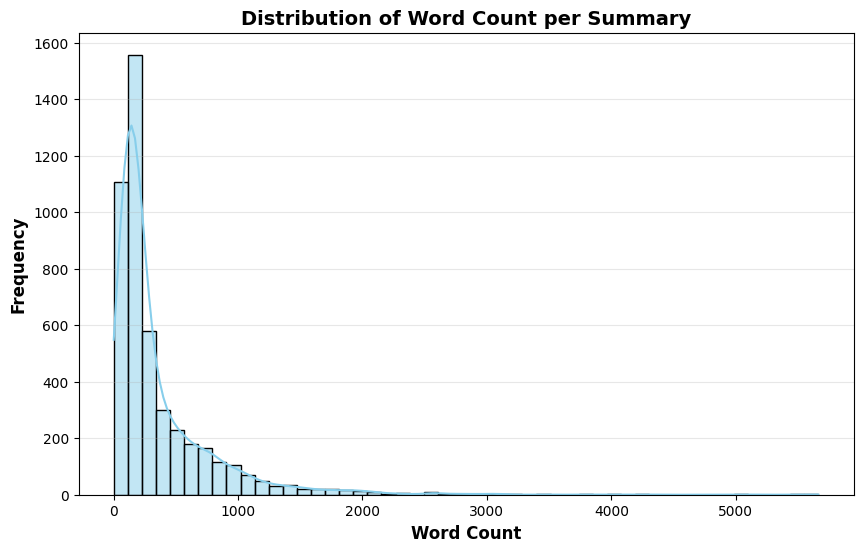


9. UNIQUE GENRES: 10

Genre distribution preview (sorted by genre ID):
genre
1      876
2      647
3      500
4      600
5      600
6     1023
7      100
8      111
9      100
10     100
Name: count, dtype: int64

✓ Data loaded and audited successfully!


82

In [ ]:
# SECTION 2: Load & Audit Data (Google Colab Optimized)
# Description: Upload dataset and perform comprehensive data audit
# Supports both direct file upload and Google Drive mounting

import io

# Direct file upload
from google.colab import files

print("\n" + "="*70)
print("UPLOAD YOUR DATASET")
print("="*70)
print("\nPlease upload your CSV file containing the book genre dataset.")
print("Expected columns: 'summary' (or 'synopsis') and 'genre'")
print("⚠️ For large files (>100MB), consider using Google Drive manually") # Updated warning

uploaded = files.upload()

# Get the uploaded filename
if len(uploaded) == 0:
    raise ValueError("No file uploaded! Please upload a CSV file.")

filename = list(uploaded.keys())[0]
print(f"\n✓ File uploaded successfully: {filename}")

# Load the dataset
df = pd.read_csv(io.BytesIO(uploaded[filename]))

# Check memory usage
print(f"\n📊 Memory usage after loading: {psutil.virtual_memory().percent}%")

print("\n" + "="*70)
print("DATA AUDIT REPORT")
print("="*70)

# Basic information
print(f"\n1. DATASET SHAPE: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"   Memory usage: {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

# Display column names
print(f"\n2. COLUMNS: {df.columns.tolist()}")

# Data types
print(f"\n3. DATA TYPES:")
print(df.dtypes)

# Missing values
print(f"\n4. MISSING VALUES:")
missing_vals = df.isnull().sum()
print(missing_vals)
print(f"\nTotal missing values: {missing_vals.sum()}")

# Check for duplicates
duplicates = df.duplicated().sum()
print(f"\n5. DUPLICATE ROWS: {duplicates}")

# Display first few rows
print(f"\n6. SAMPLE DATA:")
print(df.head(3))

# Check if the expected columns exist
text_column = None
if 'summary' in df.columns:
    text_column = 'summary'
elif 'synopsis' in df.columns:
    text_column = 'synopsis'
elif 'text' in df.columns:
    text_column = 'text'
else:
    print("\n⚠️ WARNING: Could not find 'summary', 'synopsis', or 'text' column.")
    print("Available columns:", df.columns.tolist())
    text_column = input("Enter the text column name: ")

# Rename to 'summary' for consistency
if text_column != 'summary':
    df = df.rename(columns={text_column: 'summary'})
    print(f"\n✓ Renamed '{text_column}' column to 'summary' for consistency")

# Check for genre column
if 'genre' not in df.columns:
    print("\n⚠️ WARNING: 'genre' column not found!")
    print("Available columns:", df.columns.tolist())
    genre_column = input("Enter the genre/label column name: ")
    df = df.rename(columns={genre_column: 'genre'})
    print(f"\n✓ Renamed '{genre_column}' column to 'genre' for consistency")

# Text length statistics
df['text_length'] = df['summary'].astype(str).apply(len)
print(f"\n7. TEXT LENGTH STATISTICS:")
print(df['text_length'].describe())

# Word count statistics and visualization
df['word_count'] = df['summary'].astype(str).apply(lambda x: len(x.split()))
print(f"\n8. WORD COUNT STATISTICS:")
print(df['word_count'].describe())

# Visualize word count distribution
plt.figure(figsize=(10, 6))
sns.histplot(df['word_count'], bins=50, kde=True, color='skyblue')
plt.title('Distribution of Word Count per Summary', fontsize=14, fontweight='bold')
plt.xlabel('Word Count', fontsize=12, fontweight='bold')
plt.ylabel('Frequency', fontsize=12, fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.savefig('word_count_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


# Basic genre information - Sort by index (genre number)
print(f"\n9. UNIQUE GENRES: {df['genre'].nunique()}")
print(f"\nGenre distribution preview (sorted by genre ID):")
print(df['genre'].value_counts().sort_index().head(10))

# Memory optimization warning
if df.memory_usage(deep=True).sum() / (1024**3) > 1:
    print("\n⚠️ WARNING: Dataset uses >1GB RAM. Consider:")
    print("   - Sampling the dataset")
    print("   - Using Colab Pro for more RAM")

print("\n" + "="*70)
print("✓ Data loaded and audited successfully!")
print("="*70)

# Force garbage collection
gc.collect()

#**SECTION 3: Visualize Class Imbalance**
Description: Create comprehensive visualizations to understand genre distribution before SMOTE. Shows bar plots, pie charts, and imbalance statistics.

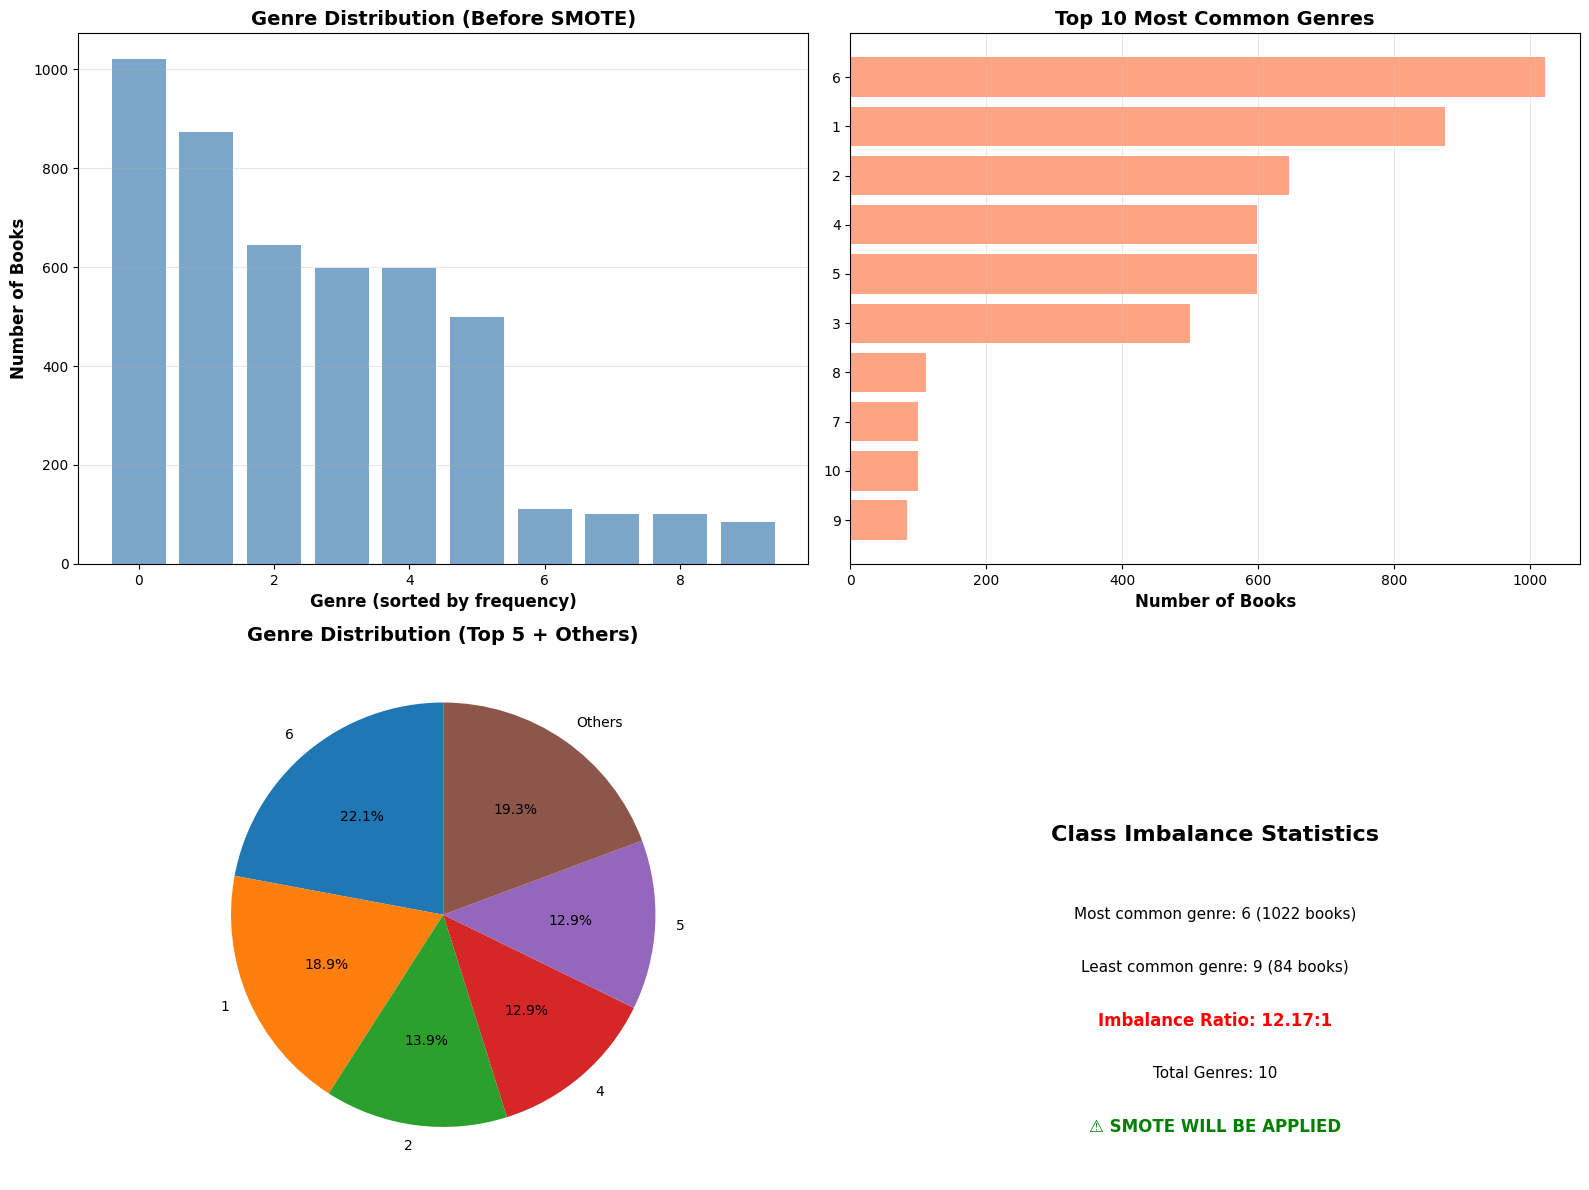


CLASS IMBALANCE ANALYSIS

Dataset is SEVERELY IMBALANCED
Imbalance Ratio: 12.17:1

🔧 Balancing Strategy:
  • SMOTE (Synthetic Minority Over-sampling Technique)
  • Generates synthetic samples for minority classes
  • Balances class distribution in feature space
  • CPU-optimized implementation

💾 Current RAM usage: 18.9%


In [ ]:
# SECTION 3: Visualize Class Imbalance
# Description: Create comprehensive visualizations to understand genre distribution before SMOTE
# Shows bar plots, pie charts, and imbalance statistics

# Calculate genre distribution
genre_counts = df['genre'].value_counts()

# Create figure with multiple subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Bar plot of genre distribution
axes[0, 0].bar(range(len(genre_counts)), genre_counts.values, color='steelblue', alpha=0.7)
axes[0, 0].set_xlabel('Genre (sorted by frequency)', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Number of Books', fontsize=12, fontweight='bold')
axes[0, 0].set_title('Genre Distribution (Before SMOTE)', fontsize=14, fontweight='bold')
axes[0, 0].grid(axis='y', alpha=0.3)

# 2. Top 10 genres
top_10 = genre_counts.head(10)
axes[0, 1].barh(range(len(top_10)), top_10.values, color='coral', alpha=0.7)
axes[0, 1].set_yticks(range(len(top_10)))
axes[0, 1].set_yticklabels(top_10.index)
axes[0, 1].set_xlabel('Number of Books', fontsize=12, fontweight='bold')
axes[0, 1].set_title('Top 10 Most Common Genres', fontsize=14, fontweight='bold')
axes[0, 1].invert_yaxis()
axes[0, 1].grid(axis='x', alpha=0.3)

# 3. Pie chart of top 5 genres
top_5 = genre_counts.head(5)
other_count = genre_counts[5:].sum()
pie_data = list(top_5.values) + [other_count]
pie_labels = list(top_5.index) + ['Others']
axes[1, 0].pie(pie_data, labels=pie_labels, autopct='%1.1f%%', startangle=90)
axes[1, 0].set_title('Genre Distribution (Top 5 + Others)', fontsize=14, fontweight='bold')

# 4. Imbalance ratio visualization
max_count = genre_counts.max()
min_count = genre_counts.min()
imbalance_ratio = max_count / min_count

axes[1, 1].text(0.5, 0.65, f'Class Imbalance Statistics',
                ha='center', va='center', fontsize=16, fontweight='bold')
axes[1, 1].text(0.5, 0.50, f'Most common genre: {genre_counts.index[0]} ({max_count} books)',
                ha='center', va='center', fontsize=11)
axes[1, 1].text(0.5, 0.40, f'Least common genre: {genre_counts.index[-1]} ({min_count} books)',
                ha='center', va='center', fontsize=11)
axes[1, 1].text(0.5, 0.30, f'Imbalance Ratio: {imbalance_ratio:.2f}:1',
                ha='center', va='center', fontsize=12, fontweight='bold', color='red')
axes[1, 1].text(0.5, 0.20, f'Total Genres: {len(genre_counts)}',
                ha='center', va='center', fontsize=11)
axes[1, 1].text(0.5, 0.10, '⚠️ SMOTE WILL BE APPLIED',
                ha='center', va='center', fontsize=12, fontweight='bold', color='green')
axes[1, 1].axis('off')

plt.tight_layout()
plt.savefig('genre_distribution_before_smote.png', dpi=300, bbox_inches='tight')
plt.show()

# Print imbalance analysis
print("\n" + "="*70)
print("CLASS IMBALANCE ANALYSIS")
print("="*70)
print(f"\nDataset is {'SEVERELY IMBALANCED' if imbalance_ratio > 10 else 'IMBALANCED'}")
print(f"Imbalance Ratio: {imbalance_ratio:.2f}:1")
print(f"\n🔧 Balancing Strategy:")
print("  • SMOTE (Synthetic Minority Over-sampling Technique)")
print("  • Generates synthetic samples for minority classes")
print("  • Balances class distribution in feature space")
print("  • CPU-optimized implementation")
print("="*70 + "\n")

# Memory check
print(f"💾 Current RAM usage: {psutil.virtual_memory().percent}%")


#**SECTION 4: Enhanced Text Cleaning with Nonsensical Word Filtering**
Description: Apply comprehensive text preprocessing with progress tracking. Removes URLs, HTML, stopwords, nonsensical words, and applies lemmatization.

In [ ]:
# SECTION 4: Enhanced Text Cleaning with Nonsensical Word Filtering
# Description: Apply comprehensive text preprocessing with progress tracking
# Removes URLs, HTML, stopwords, nonsensical words, and applies lemmatization

# Initialize lemmatizer and stopwords
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# NLTK for POS tagging
from nltk import pos_tag
from nltk.corpus import wordnet

# Ensure required NLTK resource is downloaded for POS tagging
# This is needed by nltk.pos_tag
try:
    nltk.data.find('taggers/averaged_perceptron_tagger_eng') # Check for the specific resource name
    print("✓ averaged_perceptron_tagger_eng found.")
except LookupError:
    print("Downloading averaged_perceptron_tagger_eng...") # Download the specific resource name
    nltk.download('averaged_perceptron_tagger_eng', quiet=True)
    print("✓ averaged_perceptron_tagger_eng downloaded!")


# Define nonsensical word patterns and filters
NONSENSICAL_PATTERNS = {
    'repeated_chars': lambda word: len(set(word)) <= 2 and len(word) > 3,
    'gibberish': lambda word: not any(c in 'aeiou' for c in word) and len(word) > 4,
    'numeric_heavy': lambda word: sum(c.isdigit() for c in word) > len(word) * 0.5,
}

NONSENSICAL_WORDS = {
    'aaaa', 'xxxx', 'yyyy', 'zzzz', 'hmmm', 'uhh', 'umm',
    'blah', 'yada', 'etc', 'ie', 'eg', 'qwerty', 'asdf'
}

MIN_WORD_LENGTH = 3

def is_nonsensical(word):
    """Check if a word is nonsensical"""
    if word.lower() in NONSENSICAL_WORDS:
        return True

    for pattern_name, pattern_func in NONSENSICAL_PATTERNS.items():
        if pattern_func(word):
            return True

    if len(word) < MIN_WORD_LENGTH:
        return True

    return False

def get_wordnet_pos(nltk_tag):
    """Map NLTK POS tags to WordNet POS tags"""
    if nltk_tag.startswith('J'):
        return wordnet.ADJ
    elif nltk_tag.startswith('V'):
        return wordnet.VERB
    elif nltk_tag.startswith('N'):
        return wordnet.NOUN
    elif nltk_tag.startswith('R'):
        return wordnet.ADV
    else:
        # Default to noun or None if not clearly mapped
        return wordnet.NOUN # Using noun as a default, can be changed to None

def enhanced_clean_text(text):
    """Enhanced text cleaning pipeline with POS tagging for lemmatization"""
    if pd.isna(text):
        return ""

    text = str(text).lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\.\S+', '', text)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', '', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    # Tokenize
    tokens = word_tokenize(text)

    # POS Tagging happens here
    pos_tagged_tokens = pos_tag(tokens)

    # Filter and Lemmatize pipeline
    cleaned_tokens = []
    for word, tag in pos_tagged_tokens:
        if word in stop_words:
            continue
        if is_nonsensical(word):
            continue

        # Get WordNet POS tag
        wn_tag = get_wordnet_pos(tag)

        if wn_tag: # Only lemmatize if a valid WordNet tag was found
             lemmatized = lemmatizer.lemmatize(word, wn_tag)
        else: # Fallback to default lemmatization (noun) if no specific tag is found
             lemmatized = lemmatizer.lemmatize(word)


        if 2 < len(lemmatized) < 20: # Length filtering after lemmatization
            cleaned_tokens.append(lemmatized)

    return ' '.join(cleaned_tokens)

print("="*70)
print("ENHANCED TEXT CLEANING WITH NONSENSICAL WORD FILTERING AND POS LEMMATIZATION")
print("="*70)
print("\nCleaning pipeline:")
print("  1. Remove URLs and emails")
print("  2. Remove HTML tags")
print("  3. Remove special characters")
print("  4. Remove stopwords")
print("  5. Filter nonsensical words")
print("  6. POS Tagging")
print("  7. Lemmatize (using POS tags)")
print("  8. Length filtering (3-20 characters)")
print("\n⚙️ Processing on CPU with progress bar...\n")

# Remove duplicate rows
initial_rows = len(df)
df.drop_duplicates(inplace=True)
rows_removed_duplicates = initial_rows - len(df)
print(f"\nRemoved {rows_removed_duplicates} duplicate rows.")
print(f"Current dataset size: {len(df)} rows")

# Remove rows with original summaries having fewer than 5 words
initial_count_short = len(df)
df['original_word_count'] = df['summary'].astype(str).apply(lambda x: len(x.split()))
df = df[df['original_word_count'] >= 5].drop(columns=['original_word_count']).reset_index(drop=True)
rows_removed_short = initial_count_short - len(df)
print(f"Removed {rows_removed_short} rows with less than 5 words in original summary.")
print(f"Current dataset size: {len(df)} rows")


# Apply enhanced cleaning with progress bar
tqdm.pandas(desc="Cleaning text")
df['cleaned_summary'] = df['summary'].progress_apply(enhanced_clean_text)

# Remove rows with empty cleaned text
initial_count = len(df)
df = df[df['cleaned_summary'].str.strip() != ''].reset_index(drop=True)
final_count = len(df)

print(f"\n✓ Text preprocessing complete!")
print(f"Rows removed (empty after cleaning): {initial_count - final_count}")
print(f"Final dataset size: {final_count} rows")
print(f"💾 RAM usage: {psutil.virtual_memory().percent}%\n")

# Display sample
print("BEFORE AND AFTER CLEANING (Sample):")
print("="*70)
for i in range(min(3, len(df))):
    print(f"\nOriginal [{i+1}]:")
    original = str(df['summary'].iloc[i])
    print(original[:200] + ("..." if len(original) > 200 else ""))

    print(f"\nCleaned [{i+1}]:")
    cleaned = df['cleaned_summary'].iloc[i]
    print(cleaned[:200] + ("..." if len(cleaned) > 200 else ""))
    print("-"*70)

# Calculate statistics
df['cleaned_length'] = df['cleaned_summary'].apply(len)
df['word_count'] = df['cleaned_summary'].apply(lambda x: len(x.split()))

print(f"\nCLEANED TEXT STATISTICS:")
print(df[['cleaned_length', 'word_count']].describe())

# Garbage collection
gc.collect()

✓ averaged_perceptron_tagger_eng found.
ENHANCED TEXT CLEANING WITH NONSENSICAL WORD FILTERING AND POS LEMMATIZATION

Cleaning pipeline:
  1. Remove URLs and emails
  2. Remove HTML tags
  3. Remove special characters
  4. Remove stopwords
  5. Filter nonsensical words
  6. POS Tagging
  7. Lemmatize (using POS tags)
  8. Length filtering (3-20 characters)

⚙️ Processing on CPU with progress bar...


Removed 18 duplicate rows.
Current dataset size: 4639 rows
Removed 7 rows with less than 5 words in original summary.
Current dataset size: 4632 rows


Cleaning text: 100%|██████████| 4632/4632 [01:57<00:00, 39.56it/s] 



✓ Text preprocessing complete!
Rows removed (empty after cleaning): 0
Final dataset size: 4632 rows
💾 RAM usage: 15.6%

BEFORE AND AFTER CLEANING (Sample):

Original [1]:
 Drowned Wednesday is the first Trustee among the Morrow Days who is on Arthur's side and wishes the Will to be fulfilled. She appears as a leviathan/whale and suffers from Gluttony. The book begins w...

Cleaned [1]:
drown wednesday first trustee among morrow day arthur side wish fulfil appear leviathanwhale suffers gluttony book begin leaf visit arthur discuss invitation drown wednesday send arthur admit hospital...
----------------------------------------------------------------------

Original [2]:
 As the book opens, Jason awakens on a school bus, unable to remember who or where he is, or anything about his past. He is sitting next to Piper McLean and Leo Valdez, who call him by name and say th...

Cleaned [2]:
book open jason awakens school bus unable remember anything past sit next piper mclean leo valdez call

19

#**SECTION 5: Prepare Labels**
Description: Convert genre names to numeric labels for model training. Creates bidirectional mapping between genres and numeric labels.

In [ ]:
# SECTION 5: Prepare Labels
# Description: Convert genre names to numeric labels for model training
# Creates bidirectional mapping between genres and numeric labels

print("="*70)
print("LABEL ENCODING")
print("="*70)

# Convert genre to string and clean (ensure consistent format)
df['genre'] = df['genre'].astype(str).str.strip()

# Define the user's specific genre-to-classification number mapping (1-10)
user_classification_mapping = {
    'fantasy': 1,
    'science': 2,
    'crime': 3,
    'history': 4,
    'horror': 5,
    'thriller': 6,
    'psychology': 7,
    'romance': 8,
    'sports': 9,
    'travel': 10
}

# Create a mapping from original genre number (as string) to the user's desired genre name
# Based on the audit, the original genre column contains numbers 1-10.
# We need to map these original numbers to the genre names first.
original_genre_number_to_name = {
    '1': 'fantasy',
    '2': 'science',
    '3': 'crime',
    '4': 'history',
    '5': 'horror',
    '6': 'thriller',
    '7': 'psychology',
    '8': 'romance',
    '9': 'sports',
    '10': 'travel'
}

# Map original genre numbers to genre names
df['genre_name'] = df['genre'].map(original_genre_number_to_name)

# Now, create the 0-indexed label mapping based on the user's classification order (1-10)
# We will sort the user's mapping by the classification number to ensure consistent 0-indexing
sorted_user_mapping_items = sorted(user_classification_mapping.items(), key=lambda item: item[1])

# Create the label mapping from genre name to 0-indexed label
# This mapping will be used internally by the model
label_mapping = {genre_name: i for i, (genre_name, classification_num) in enumerate(sorted_user_mapping_items)}

# Create a reverse mapping from 0-indexed label to a tuple (genre_name, classification_num) for display
display_mapping = {i: (genre_name, classification_num) for i, (genre_name, classification_num) in enumerate(sorted_user_mapping_items)}

num_labels = len(label_mapping)

# Apply the 0-indexed label mapping to get the 'label' column
df['label'] = df['genre_name'].map(label_mapping).astype(int)

print(f"\nLabel Mapping (0-indexed label: Genre Name (User Classification #)):")
# Sort by 0-indexed label for consistent display
for label_id in sorted(display_mapping.keys()):
    genre_name, classification_num = display_mapping[label_id]
    count = (df['label'] == label_id).sum()
    print(f"Label {label_id:2d}: {genre_name:<20s} (Classification {classification_num:2d}) ({count:5d} samples)")

print(f"\n✓ Successfully mapped {num_labels} genres!")
print(f"✓ Total dataset size: {len(df)}")
print("="*70 + "\n")

# The 'label_mapping' dictionary now maps genre names to 0-indexed labels for model use.
# The 'display_mapping' dictionary maps 0-indexed labels to (genre_name, classification_num) for output.
# We will use 'display_mapping' in subsequent sections to show both.

LABEL ENCODING

Label Mapping (0-indexed label: Genre Name (User Classification #)):
Label  0: fantasy              (Classification  1) (  874 samples)
Label  1: science              (Classification  2) (  645 samples)
Label  2: crime                (Classification  3) (  500 samples)
Label  3: history              (Classification  4) (  598 samples)
Label  4: horror               (Classification  5) (  598 samples)
Label  5: thriller             (Classification  6) ( 1022 samples)
Label  6: psychology           (Classification  7) (  100 samples)
Label  7: romance              (Classification  8) (  111 samples)
Label  8: sports               (Classification  9) (   84 samples)
Label  9: travel               (Classification 10) (  100 samples)

✓ Successfully mapped 10 genres!
✓ Total dataset size: 4632



#**SECTION 6: Train-Test Split**
Description: Split data with stratification to maintain genre proportions. Uses 80/20 split with stratification for balanced class representation.

In [ ]:
# SECTION 6: Train-Test Split
# Description: Split data with stratification to maintain genre proportions
# Uses 80/20 split with stratification for balanced class representation

# Perform stratified train-test split
X = df['cleaned_summary']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("="*70)
print("TRAIN-TEST SPLIT SUMMARY")
print("="*70)
print(f"\nTotal samples: {len(df)}")
print(f"Training samples: {len(X_train)} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Testing samples: {len(X_test)} ({len(X_test)/len(df)*100:.1f}%)")

# Check distribution
train_genre_dist = pd.Series(y_train).value_counts().sort_index()
test_genre_dist = pd.Series(y_test).value_counts().sort_index()

print(f"\n{'='*70}")
print("GENRE DISTRIBUTION IN SPLITS (Top 10)")
print(f"{'='*70}")
print("\nTraining set:")
for label_id in train_genre_dist.head(10).index:
    # Use display_mapping from Section 5 to get genre name
    genre_name, classification_num = display_mapping[label_id]
    count = train_genre_dist[label_id]
    print(f"  Label {label_id:2d} ({genre_name:<20s}): {count:5d} samples")

print("\nTesting set:")
for label_id in test_genre_dist.head(10).index:
     # Use display_mapping from Section 5 to get genre name
    genre_name, classification_num = display_mapping[label_id]
    count = test_genre_dist[label_id]
    print(f"  Label {label_id:2d} ({genre_name:<20s}): {count:5d} samples")

print("\n✓ Train-test split complete!")
print(f"💾 RAM usage: {psutil.virtual_memory().percent}%")
print("="*70 + "\n")

TRAIN-TEST SPLIT SUMMARY

Total samples: 4632
Training samples: 3705 (80.0%)
Testing samples: 927 (20.0%)

GENRE DISTRIBUTION IN SPLITS (Top 10)

Training set:
  Label  0 (fantasy             ):   699 samples
  Label  1 (science             ):   516 samples
  Label  2 (crime               ):   400 samples
  Label  3 (history             ):   478 samples
  Label  4 (horror              ):   478 samples
  Label  5 (thriller            ):   818 samples
  Label  6 (psychology          ):    80 samples
  Label  7 (romance             ):    89 samples
  Label  8 (sports              ):    67 samples
  Label  9 (travel              ):    80 samples

Testing set:
  Label  0 (fantasy             ):   175 samples
  Label  1 (science             ):   129 samples
  Label  2 (crime               ):   100 samples
  Label  3 (history             ):   120 samples
  Label  4 (horror              ):   120 samples
  Label  5 (thriller            ):   204 samples
  Label  6 (psychology          ):    20 s

#**SECTION 7: TF-IDF Vectorization (CPU-Optimized)**
Description: Convert cleaned text to TF-IDF numerical features using CPU. Creates sparse matrix with 5000 features using unigrams and bigrams.

In [ ]:
# SECTION 7: TF-IDF Vectorization (CPU-Optimized)
# Description: Convert cleaned text to TF-IDF numerical features using CPU
# Creates sparse matrix with 5000 features using unigrams and bigrams

print("="*70)
print("TF-IDF VECTORIZATION (CPU)")
print("="*70)

# Initialize TF-IDF Vectorizer (CPU-only, memory-efficient)
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,        # Limit to 5000 features for memory efficiency
    min_df=2,                 # Ignore terms appearing in fewer than 2 documents
    max_df=0.8,               # Ignore terms appearing in more than 80% of documents
    ngram_range=(1, 2),       # Use unigrams and bigrams
    sublinear_tf=True,        # Apply sublinear tf scaling (1 + log(tf))
    strip_accents='unicode',
    lowercase=True,
    stop_words='english'
)

print("\n⚙️ Fitting TF-IDF on training data (CPU)...")
print("This may take 1-3 minutes depending on dataset size...\n")

start_time = time.time()

# Fit on training data and transform both train and test
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

elapsed = time.time() - start_time

print(f"\n✓ TF-IDF vectorization complete!")
print(f"⏱️ Time taken: {elapsed:.2f} seconds")
print(f"\nFeature Matrix Statistics:")
print(f"  Training shape: {X_train_tfidf.shape}")
print(f"  Testing shape: {X_test_tfidf.shape}")
print(f"  Total features: {len(tfidf_vectorizer.get_feature_names_out())}")
print(f"  Sparsity: {(1.0 - X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1])) * 100:.2f}%")
print(f"  Memory size: {X_train_tfidf.data.nbytes / (1024**2):.2f} MB")

# Show sample features
print(f"\nSample features (first 20):")
feature_names = tfidf_vectorizer.get_feature_names_out()
print(feature_names[:20])

print(f"\n💾 RAM usage: {psutil.virtual_memory().percent}%")
print("="*70 + "\n")

# Garbage collection
gc.collect()


TF-IDF VECTORIZATION (CPU)

⚙️ Fitting TF-IDF on training data (CPU)...
This may take 1-3 minutes depending on dataset size...


✓ TF-IDF vectorization complete!
⏱️ Time taken: 5.68 seconds

Feature Matrix Statistics:
  Training shape: (3705, 5000)
  Testing shape: (927, 5000)
  Total features: 5000
  Sparsity: 98.12%
  Memory size: 2.65 MB

Sample features (first 20):
['aaron' 'abandon' 'abbey' 'abbot' 'abby' 'abduct' 'ability' 'able'
 'able escape' 'aboard' 'aboard ship' 'abortion' 'abraham' 'abroad'
 'abruptly' 'absence' 'absolute' 'absolutely' 'absorb' 'abuse']

💾 RAM usage: 15.4%



0

#**SECTION 8: Apply SMOTE for Data Balancing (CPU-Optimized)**
Description: Generate synthetic samples for minority classes using CPU-based SMOTE. Balances class distribution by creating synthetic samples in feature space.

SMOTE DATA BALANCING (CPU)

Original training distribution:
Smallest class size in training data: 67 samples
  Label  0 (fantasy                       ):   699 samples
  Label  1 (science                       ):   516 samples
  Label  2 (crime                         ):   400 samples
  Label  3 (history                       ):   478 samples
  Label  4 (horror                        ):   478 samples
  Label  5 (thriller                      ):   818 samples
  Label  6 (psychology                    ):    80 samples
  Label  7 (romance                       ):    89 samples
  Label  8 (sports                        ):    67 samples
  Label  9 (travel                        ):    80 samples

⚙️ Applying SMOTE on CPU...
This operation is CPU-intensive and may take several minutes...

✓ SMOTE complete!
⏱️ Time taken: 0.16 seconds (0.0 minutes)

Balanced training distribution (showing first 10):
  Label  0 (fantasy                       ):   818 samples (+ 119 synthetic)
  Label  1 (scienc

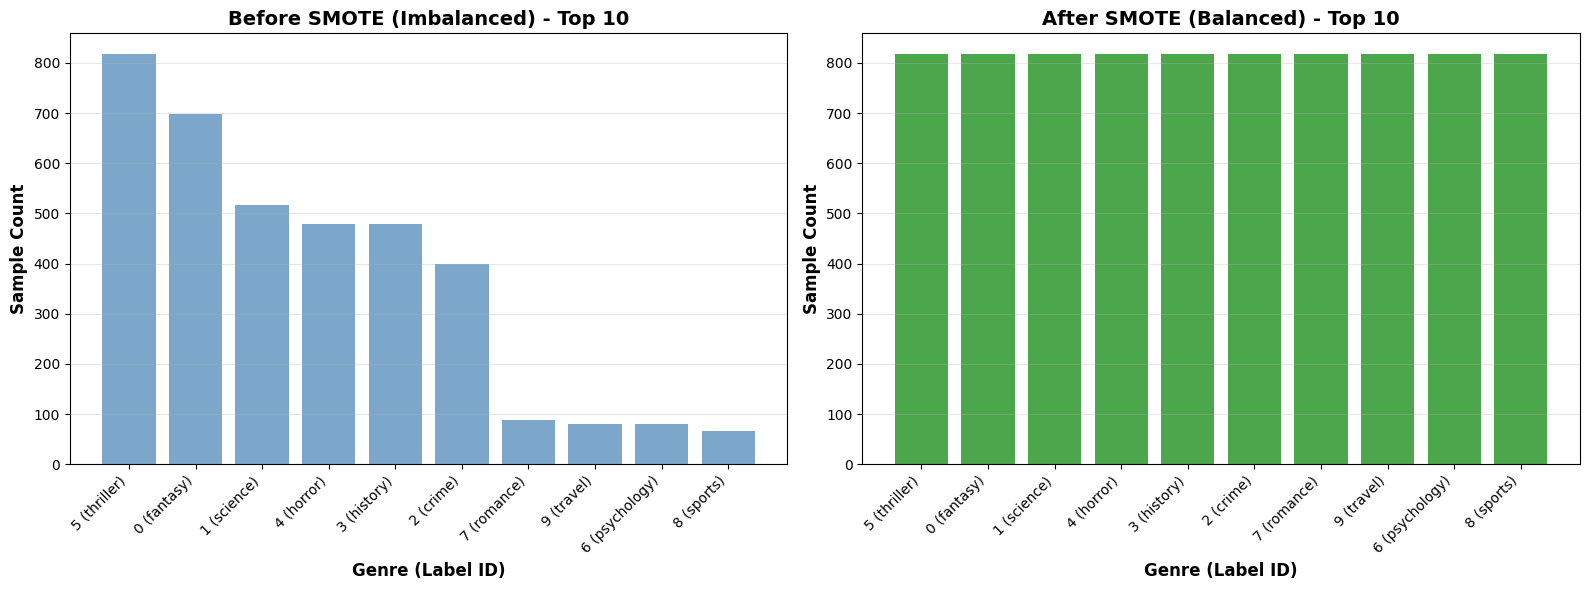


✓ Data balancing complete using SMOTE!
💾 RAM usage: 15.5%



48

In [ ]:
# SECTION 8: Apply SMOTE for Data Balancing (CPU-Optimized)
# Description: Generate synthetic samples for minority classes using CPU-based SMOTE
# Balances class distribution by creating synthetic samples in feature space.

print("="*70)
print("SMOTE DATA BALANCING (CPU)")
print("="*70)

# Check original distribution
print("\nOriginal training distribution:")
original_dist = Counter(y_train)
# Find the smallest class size (though not strictly needed for SMOTE's default auto strategy)
min_class_size = min(original_dist.values())
print(f"Smallest class size in training data: {min_class_size} samples")

for label_id in sorted(original_dist.keys())[:10]:  # Show top 10
    # Use display_mapping from Section 5 to get genre name
    genre_name, classification_num = display_mapping[label_id]
    count = original_dist[label_id]
    print(f"  Label {label_id:2d} ({genre_name:<30s}): {count:5d} samples")


# Memory warning for large datasets
estimated_samples_after = max(original_dist.values()) * len(original_dist)
if estimated_samples_after > 100000:
    print(f"\n⚠️ WARNING: SMOTE will generate ~{estimated_samples_after:,} samples")
    print("This may take 5-10 minutes on CPU and use significant RAM.")
    print("Consider using sampling_strategy to limit oversampling.")

# Initialize SMOTE (CPU-optimized)
from imblearn.over_sampling import SMOTE # Import SMOTE

smote = SMOTE(
    sampling_strategy='auto',  # Balance all classes to majority class size
    random_state=42,
    k_neighbors=5 # Default value for SMOTE
    # NOTE: n_jobs is not supported in SMOTE
)

# Check if k_neighbors is compatible with the smallest class size (relevant for SMOTE)
if smote.k_neighbors > min_class_size:
     print(f"\n⚠️ WARNING: k_neighbors ({smote.k_neighbors}) is greater than the smallest class size ({min_class_size}).")
     print("   SMOTE may not generate samples for this class. Consider reducing k_neighbors.")
     # Optionally adjust k_neighbors here, or let it fail to highlight the issue
     # smote.k_neighbors = max(1, min_class_size - 1) # Adjusting k_neighbors dynamically


print(f"\n⚙️ Applying SMOTE on CPU...")
print("This operation is CPU-intensive and may take several minutes...\n")

start_time = time.time()

# Apply SMOTE
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_tfidf, y_train)

elapsed = time.time() - start_time

# Check new distribution
print(f"✓ SMOTE complete!")
print(f"⏱️ Time taken: {elapsed:.2f} seconds ({elapsed/60:.1f} minutes)")
print(f"\nBalanced training distribution (showing first 10):")
balanced_dist = Counter(y_train_balanced)
for label_id in sorted(balanced_dist.keys())[:10]:
    # Use display_mapping from Section 5 to get genre name
    genre_name, classification_num = display_mapping[label_id]
    original_count = original_dist.get(label_id, 0)
    new_count = balanced_dist[label_id]
    synthetic = new_count - original_count
    print(f"  Label {label_id:2d} ({genre_name:<30s}): {new_count:5d} samples (+{synthetic:4d} synthetic)")


print(f"\nDataset size:")
print(f"  Original training samples: {X_train_tfidf.shape[0]:,}")
print(f"  Balanced training samples: {X_train_balanced.shape[0]:,}")
print(f"  Total synthetic samples added: {X_train_balanced.shape[0] - X_train_tfidf.shape[0]:,}")
print(f"  Memory usage: {X_train_balanced.data.nbytes / (1024**2):.2f} MB")

# Visualize before and after
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Show top 10 genres only for readability in bar plot
top_genres_labels = sorted(original_dist.keys(), key=lambda x: original_dist[x], reverse=True)[:10]
# Get corresponding genre names for plotting
top_genres_names = [display_mapping[label_id][0] for label_id in top_genres_labels]


# Before SMOTE
original_counts = [original_dist.get(label_id, 0) for label_id in top_genres_labels]

ax1.bar(range(len(original_counts)), original_counts, color='steelblue', alpha=0.7)
ax1.set_xlabel('Genre (Label ID)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Sample Count', fontsize=12, fontweight='bold')
ax1.set_title('Before SMOTE (Imbalanced) - Top 10', fontsize=14, fontweight='bold')
ax1.set_xticks(range(len(top_genres_labels)))
ax1.set_xticklabels([f"{label_id} ({name[:10]}...)" if len(name) > 10 else f"{label_id} ({name})" for label_id, name in zip(top_genres_labels, top_genres_names)], rotation=45, ha='right')
ax1.grid(axis='y', alpha=0.3)


# After SMOTE
balanced_counts = [balanced_dist.get(label_id, 0) for label_id in top_genres_labels]

ax2.bar(range(len(balanced_counts)), balanced_counts, color='green', alpha=0.7)
ax2.set_xlabel('Genre (Label ID)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Sample Count', fontsize=12, fontweight='bold')
ax2.set_title('After SMOTE (Balanced) - Top 10', fontsize=14, fontweight='bold')
ax2.set_xticks(range(len(top_genres_labels)))
ax2.set_xticklabels([f"{label_id} ({name[:10]}...)" if len(name) > 10 else f"{label_id} ({name})" for label_id, name in zip(top_genres_labels, top_genres_names)], rotation=45, ha='right')
ax2.grid(axis='y', alpha=0.3)


plt.tight_layout()
plt.savefig('smote_comparison.png', dpi=300, bbox_inches='tight') # Reverted filename
plt.show()

print("\n" + "="*70)
print("✓ Data balancing complete using SMOTE!") # Reverted message
print(f"💾 RAM usage: {psutil.virtual_memory().percent}%")
print("="*70 + "\n")

# Garbage collection
gc.collect()

#**SECTION 9: Train Logistic Regression Model (CPU)**
Description: Train multinomial logistic regression using all CPU cores. Uses L-BFGS solver optimized for multiclass classification.

In [ ]:
# SECTION 9: Train Logistic Regression Model (CPU)
# Description: Train multinomial logistic regression using all CPU cores
# Uses L-BFGS solver optimized for multiclass classification

print("="*70)
print("LOGISTIC REGRESSION TRAINING (CPU)")
print("="*70)

# Initialize Logistic Regression (CPU-optimized)
lr_model = LogisticRegression(
    max_iter=1000,
    solver='lbfgs',           # CPU-efficient solver
    multi_class='multinomial',
    random_state=42,
    n_jobs=-1,                # Use all CPU cores
    verbose=1                 # Show progress
)

print(f"\n⚙️ Training on {psutil.cpu_count()} CPU cores")
print("Training Logistic Regression on SMOTE-balanced data...")
print("This may take 5-15 minutes depending on dataset size...\n")

start_time = time.time()

# Train the model
lr_model.fit(X_train_balanced, y_train_balanced)

elapsed = time.time() - start_time

print(f"\n✓ Training complete!")
print(f"⏱️ Training time: {elapsed:.2f} seconds ({elapsed/60:.1f} minutes)")

# Model parameters
print(f"\nModel parameters:")
print(f"  Number of classes: {len(lr_model.classes_)}")
print(f"  Number of features: {X_train_balanced.shape[1]}")
print(f"  Solver: {lr_model.solver}")
print(f"  Max iterations: {lr_model.max_iter}")
print(f"  Actual iterations: {lr_model.n_iter_[0]}")
print(f"  Convergence: {'✓ Converged' if lr_model.n_iter_[0] < lr_model.max_iter else '⚠️ Did not converge'}")
print(f"  CPU cores used: {psutil.cpu_count()}")

# Save the model
print("\n💾 Saving models...")
joblib.dump(lr_model, 'logistic_regression_smote_model.pkl')
joblib.dump(tfidf_vectorizer, 'tfidf_vectorizer.pkl')
joblib.dump(label_mapping, 'label_mapping.pkl')

print("✓ Model saved to 'logistic_regression_smote_model.pkl'")
print("✓ Vectorizer saved to 'tfidf_vectorizer.pkl'")
print("✓ Label mapping saved to 'label_mapping.pkl'")

print(f"\n💾 RAM usage: {psutil.virtual_memory().percent}%")
print("="*70 + "\n")

# Garbage collection
gc.collect()


LOGISTIC REGRESSION TRAINING (CPU)

⚙️ Training on 2 CPU cores
Training Logistic Regression on SMOTE-balanced data...
This may take 5-15 minutes depending on dataset size...



[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.



✓ Training complete!
⏱️ Training time: 3.84 seconds (0.1 minutes)

Model parameters:
  Number of classes: 10
  Number of features: 5000
  Solver: lbfgs
  Max iterations: 1000
  Actual iterations: 48
  Convergence: ✓ Converged
  CPU cores used: 2

💾 Saving models...
✓ Model saved to 'logistic_regression_smote_model.pkl'
✓ Vectorizer saved to 'tfidf_vectorizer.pkl'
✓ Label mapping saved to 'label_mapping.pkl'

💾 RAM usage: 16.7%



0

#**SECTION 10: Model Evaluation on Test Set**
Description: Evaluate model performance with comprehensive metrics and visualizations. Generates classification report, confusion matrix, and per-class performance.

MODEL EVALUATION ON TEST SET

⚙️ Making predictions on CPU...
⏱️ Prediction time: 0.00 seconds

OVERALL PERFORMANCE METRICS
Accuracy:           0.6980 (69.80%)
F1-Score (Macro):   0.6921
F1-Score (Weighted):0.6990
Precision:          0.7032
Recall:             0.6980

DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

     fantasy       0.81      0.73      0.77       175
     science       0.76      0.67      0.71       129
       crime       0.66      0.72      0.69       100
     history       0.66      0.76      0.71       120
      horror       0.66      0.65      0.65       120
    thriller       0.66      0.68      0.67       204
  psychology       0.74      0.85      0.79        20
     romance       0.42      0.45      0.43        22
      sports       0.87      0.76      0.81        17
      travel       0.72      0.65      0.68        20

    accuracy                           0.70       927
   macro avg       0.70      0.69      0.69       

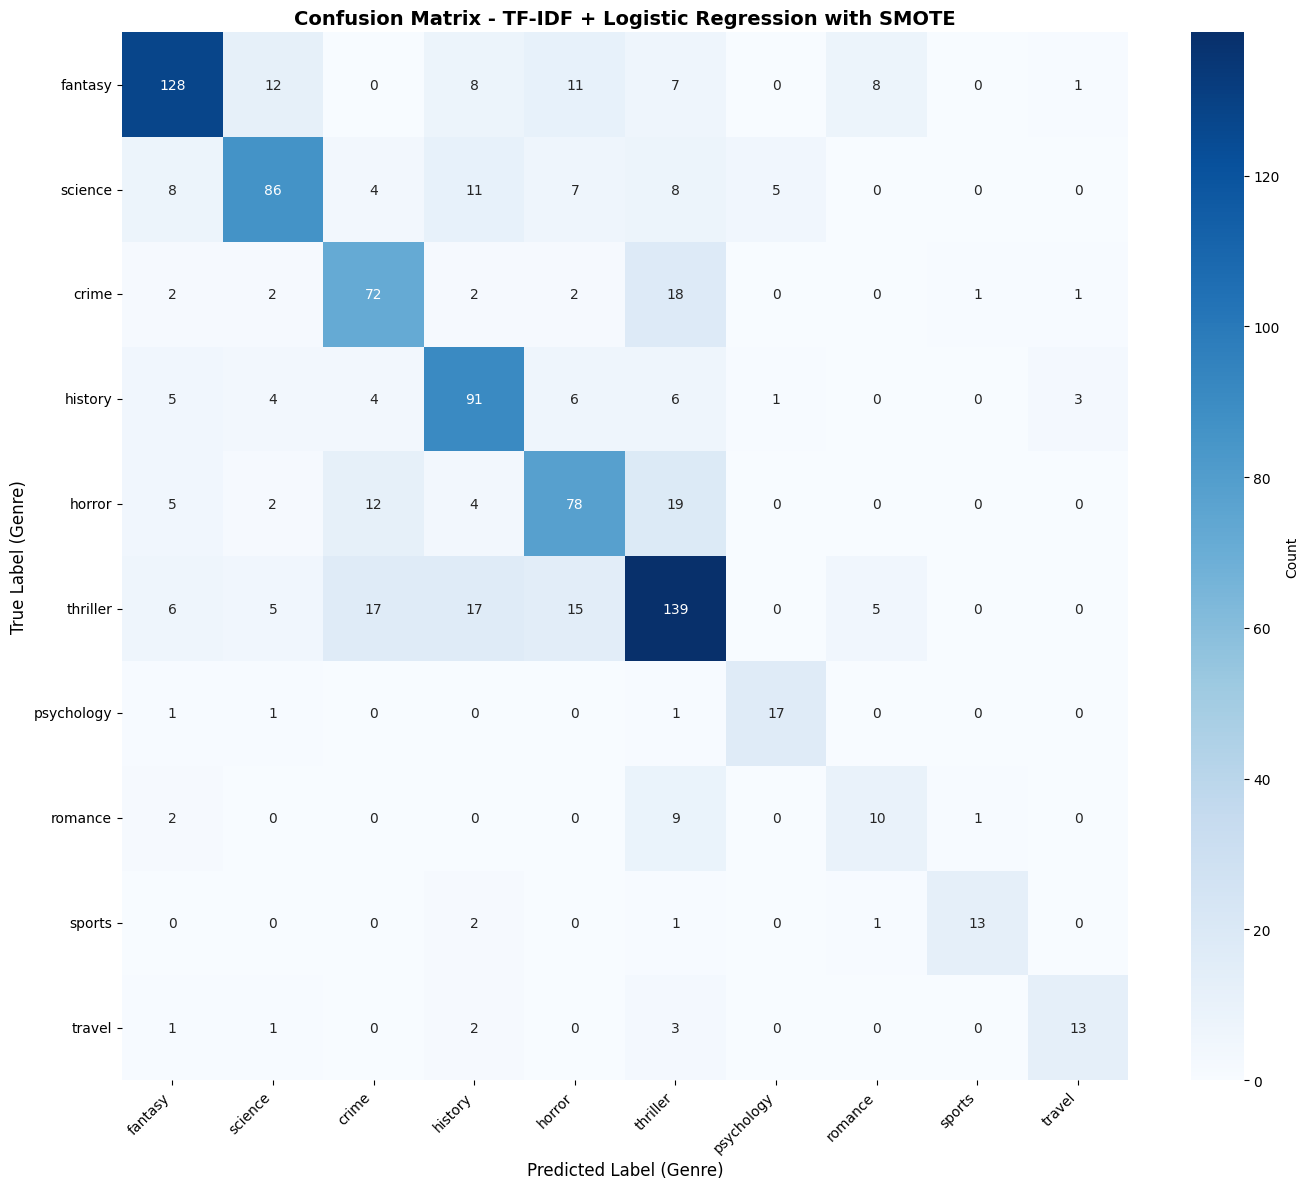

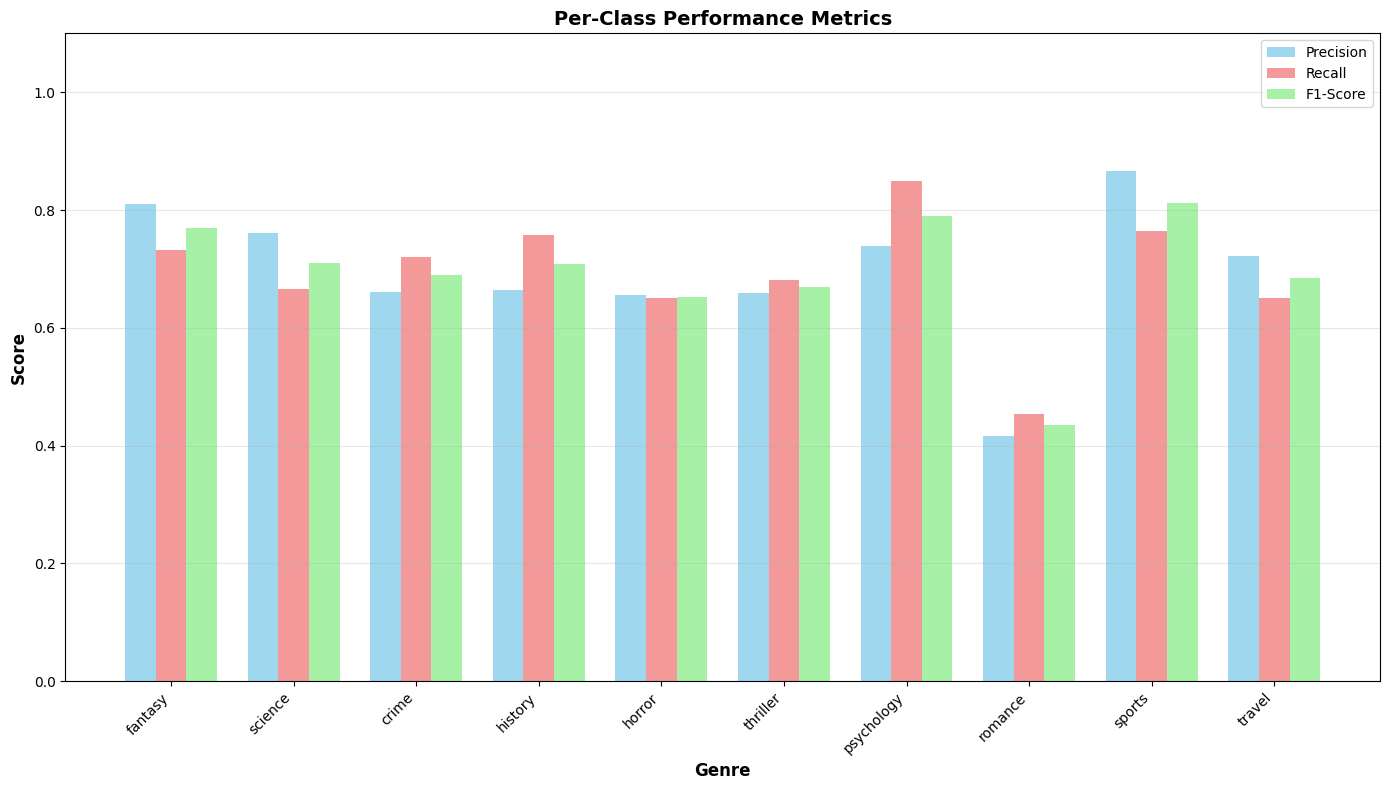


✓ Evaluation complete!
💾 RAM usage: 16.7%


In [ ]:
# SECTION 10: Model Evaluation on Test Set
# Description: Evaluate model performance with comprehensive metrics and visualizations
# Generates classification report, confusion matrix, and per-class performance

print("="*70)
print("MODEL EVALUATION ON TEST SET")
print("="*70)

print("\n⚙️ Making predictions on CPU...")
start_time = time.time()

# Make predictions
y_pred = lr_model.predict(X_test_tfidf)
y_pred_proba = lr_model.predict_proba(X_test_tfidf)

elapsed = time.time() - start_time
print(f"⏱️ Prediction time: {elapsed:.2f} seconds")

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')
precision_weighted = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall_weighted = recall_score(y_test, y_pred, average='weighted', zero_division=0)

print(f"\n{'='*70}")
print("OVERALL PERFORMANCE METRICS")
print(f"{'='*70}")
print(f"Accuracy:           {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"F1-Score (Macro):   {f1_macro:.4f}")
print(f"F1-Score (Weighted):{f1_weighted:.4f}")
print(f"Precision:          {precision_weighted:.4f}")
print(f"Recall:             {recall_weighted:.4f}")
print(f"{'='*70}\n")

# Classification report
print("DETAILED CLASSIFICATION REPORT")
print("="*70)

# Correctly construct target_names as a list of strings using display_mapping
# The keys of display_mapping are the 0-indexed label IDs
# The values are tuples (genre_name, classification_num)
target_names_for_report = [display_mapping[label_id][0] for label_id in sorted(display_mapping.keys())]


# If too many genres, show summary or top N (optional, but good practice)
if len(target_names_for_report) > 20:
    print(f"⚠️ Dataset has {len(target_names_for_report)} genres. Showing report for all, but plots for top N.\n")
    print(classification_report(y_test, y_pred,
                               target_names=target_names_for_report, zero_division=0))
else:
    print(classification_report(y_test, y_pred, target_names=target_names_for_report, zero_division=0))

# Confusion Matrix (for reasonable number of classes)
if len(target_names_for_report) <= 30: # Use genre names only for readability in plot
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(14, 12))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=target_names_for_report, yticklabels=target_names_for_report,
                cbar_kws={'label': 'Count'})
    plt.title('Confusion Matrix - TF-IDF + Logistic Regression with SMOTE',
              fontsize=14, fontweight='bold')
    plt.ylabel('True Label (Genre)', fontsize=12)
    plt.xlabel('Predicted Label (Genre)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig('confusion_matrix_tfidf_smote.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print(f"\n⚠️ Skipping confusion matrix visualization ({len(target_names_for_report)} genres is too many)")

# Per-class performance (top 15 by default, or all if less than 15)
report_dict = classification_report(y_test, y_pred,
                                   target_names=target_names_for_report,
                                   output_dict=True,
                                   zero_division=0)

# Get the list of classes present in the report_dict (excluding accuracy, macro avg, weighted avg)
report_classes = [key for key in report_dict.keys() if key not in ['accuracy', 'macro avg', 'weighted avg']]

# Sort classes by label ID to match the order in Section 5/6 for plotting
classes_to_plot_names = [display_mapping[label_id][0] for label_id in sorted(display_mapping.keys())]

# Ensure we only plot classes that were actually in the test set and report
classes_to_plot_names = [name for name in classes_to_plot_names if name in report_classes]

# Limit to top 15 if there are many classes (optional, but keeps plot readable)
# Let's plot all classes if 15 or less, otherwise plot all
# if len(classes_to_plot_names) > 15:
#      classes_to_plot_names = [display_mapping[label_id][0] for label_id in sorted(display_mapping.keys())[:15]]
#      classes_to_plot_names = [name for name in classes_to_plot_names if name in report_classes]


f1_scores = [report_dict[name]['f1-score'] for name in classes_to_plot_names]
precisions = [report_dict[name]['precision'] for name in classes_to_plot_names]
recalls = [report_dict[name]['recall'] for name in classes_to_plot_names]

fig, ax = plt.subplots(figsize=(14, 8))
x = np.arange(len(classes_to_plot_names))
width = 0.25

bars1 = ax.bar(x - width, precisions, width, label='Precision', alpha=0.8, color='skyblue')
bars2 = ax.bar(x, recalls, width, label='Recall', alpha=0.8, color='lightcoral')
bars3 = ax.bar(x + width, f1_scores, width, label='F1-Score', alpha=0.8, color='lightgreen')

ax.set_xlabel('Genre', fontsize=12, fontweight='bold')
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_title('Per-Class Performance Metrics',
             fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(classes_to_plot_names, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1.1])

plt.tight_layout()
plt.savefig('per_class_performance_tfidf_smote.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Evaluation complete!")
print(f"💾 RAM usage: {psutil.virtual_memory().percent}%")

#**SECTION 11: Feature Interpretation (Top TF-IDF Words per Genre)**
Description: Identify and visualize the most important words for each genre classification. Shows top TF-IDF features that drive predictions.

FEATURE IMPORTANCE ANALYSIS

Top 15 most important words per genre (showing first 10 genres):

Label  0 (fantasy):
  magic                    : 3.8105
  dragon                   : 2.9321
  kingdom                  : 2.8712
  magical                  : 2.8660
  power                    : 2.7809
  wizard                   : 2.5938
  king                     : 2.3072
  god                      : 2.0109
  magician                 : 1.9321
  fantasy                  : 1.9063
  evil                     : 1.8621
  dark                     : 1.8364
  adventure                : 1.8289
  world                    : 1.8093
  lord                     : 1.7449

Label  1 (science):
  planet                   : 4.8088
  earth                    : 3.7430
  alien                    : 3.5406
  future                   : 3.2738
  universe                 : 3.1072
  space                    : 3.0999
  human                    : 3.0062
  doctor                   : 2.7464
  science                  : 2.6967


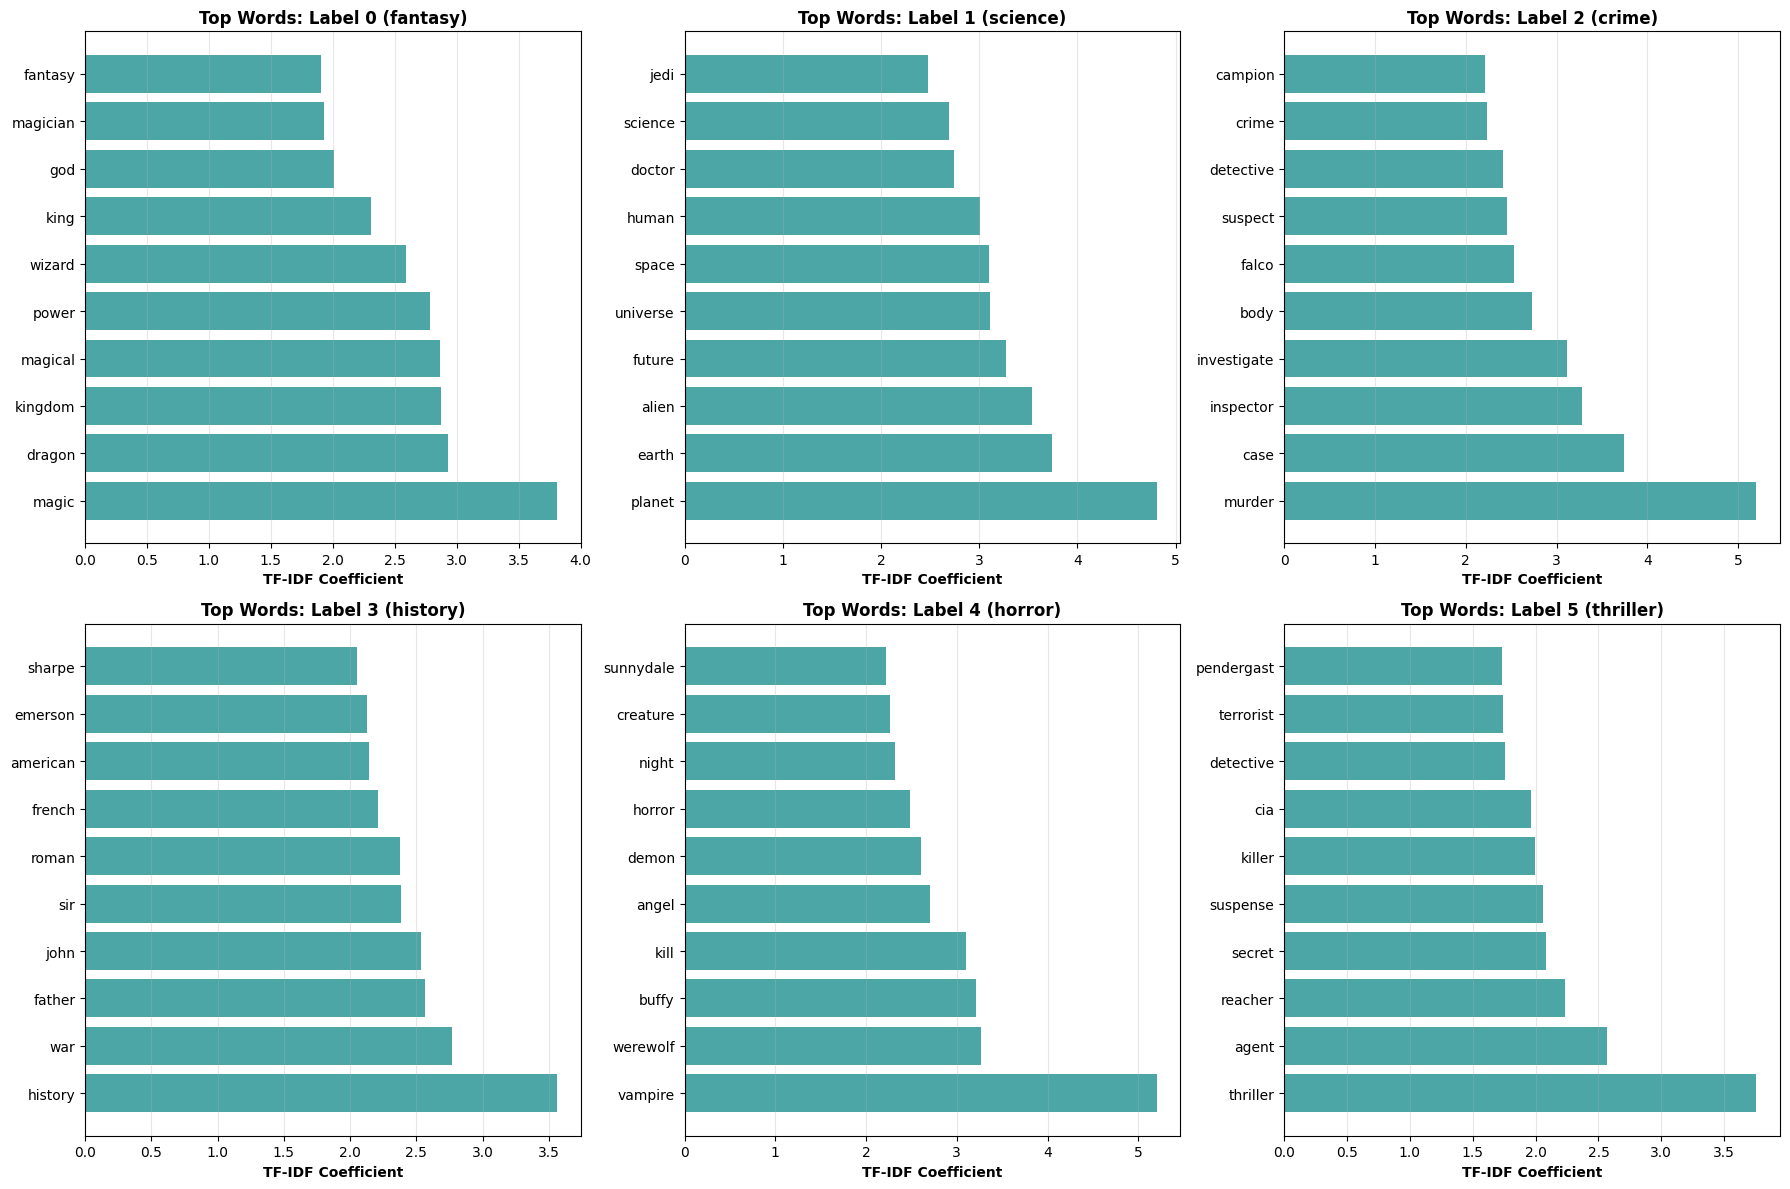

In [ ]:
# SECTION 11: Feature Interpretation (Top TF-IDF Words per Genre)
# Description: Identify and visualize the most important words for each genre classification
# Shows top TF-IDF features that drive predictions

print("="*70)
print("FEATURE IMPORTANCE ANALYSIS")
print("="*70)

# Get feature names
feature_names = np.array(tfidf_vectorizer.get_feature_names_out())

# Get coefficients for each class
coefficients = lr_model.coef_

print(f"\nTop 15 most important words per genre (showing first 10 genres):\n")

genres_to_show = min(10, len(display_mapping)) # Use display_mapping for accurate count
for class_idx in sorted(display_mapping.keys())[:genres_to_show]: # Iterate by label ID
    # Get genre name and classification number using display_mapping
    genre_name, classification_num = display_mapping[class_idx]
    class_coefs = coefficients[class_idx]

    # Get top 15 positive coefficients (most indicative)
    top_indices = np.argsort(class_coefs)[-15:][::-1]
    top_features = feature_names[top_indices]
    top_scores = class_coefs[top_indices]

    print(f"Label {class_idx:2d} ({genre_name}):") # Print label ID and genre name
    for feat, score in zip(top_features, top_scores):
        print(f"  {feat:<25s}: {score:.4f}")
    print()

# Visualize top words for first 6 genres
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

# Plot for first 6 genres based on sorted label IDs
genres_to_plot_ids = sorted(display_mapping.keys())[:min(6, len(display_mapping))]

for idx, class_idx in enumerate(genres_to_plot_ids):
    genre_name, classification_num = display_mapping[class_idx]
    class_coefs = coefficients[class_idx]

    # Get top 10 features
    top_indices = np.argsort(class_coefs)[-10:]
    top_features = feature_names[top_indices]
    top_scores = class_coefs[top_indices]

    axes[idx].barh(range(len(top_features)), top_scores, color='teal', alpha=0.7)
    axes[idx].set_yticks(range(len(top_features)))
    axes[idx].set_yticklabels(top_features)
    axes[idx].set_xlabel('TF-IDF Coefficient', fontweight='bold')
    axes[idx].set_title(f'Top Words: Label {class_idx} ({genre_name})', fontweight='bold') # Include label ID and name
    axes[idx].invert_yaxis()
    axes[idx].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('top_words_per_genre.png', dpi=300, bbox_inches='tight')
plt.show()

print("="*70 + "\n")

#**SECTION 12: 5-Fold Cross-Validation (CPU) - FIXED**
Description: Robust validation using stratified 5-fold cross-validation with SMOTE in each fold. Provides comprehensive performance assessment.

5-FOLD CROSS-VALIDATION (CPU)

⚙️ Performing 5-fold cross-validation using 2 CPU cores
This will train 5 models and may take 10-30 minutes...

Fold 1/5...
  Accuracy: 0.7206, F1-Weighted: 0.7201
  ⏱️ Fold time: 3.82 seconds (0.1 minutes)

Fold 2/5...
  Accuracy: 0.7233, F1-Weighted: 0.7233
  ⏱️ Fold time: 4.10 seconds (0.1 minutes)

Fold 3/5...
  Accuracy: 0.6950, F1-Weighted: 0.6938
  ⏱️ Fold time: 2.25 seconds (0.0 minutes)

Fold 4/5...
  Accuracy: 0.6815, F1-Weighted: 0.6829
  ⏱️ Fold time: 2.18 seconds (0.0 minutes)

Fold 5/5...
  Accuracy: 0.7166, F1-Weighted: 0.7154
  ⏱️ Fold time: 2.09 seconds (0.0 minutes)


CROSS-VALIDATION SUMMARY

⏱️ Total CV time: 14.45 seconds (0.2 minutes)

Mean ± Std Performance Across 5 Folds:
ACCURACY       : 0.7074 ± 0.0183
F1_MACRO       : 0.6974 ± 0.0287
F1_WEIGHTED    : 0.7071 ± 0.0178
PRECISION      : 0.7111 ± 0.0173
RECALL         : 0.7074 ± 0.0183

✓ Cross-validation results saved to 'cross_validation_results_tfidf_smote.csv'
💾 RAM usage: 18.2%


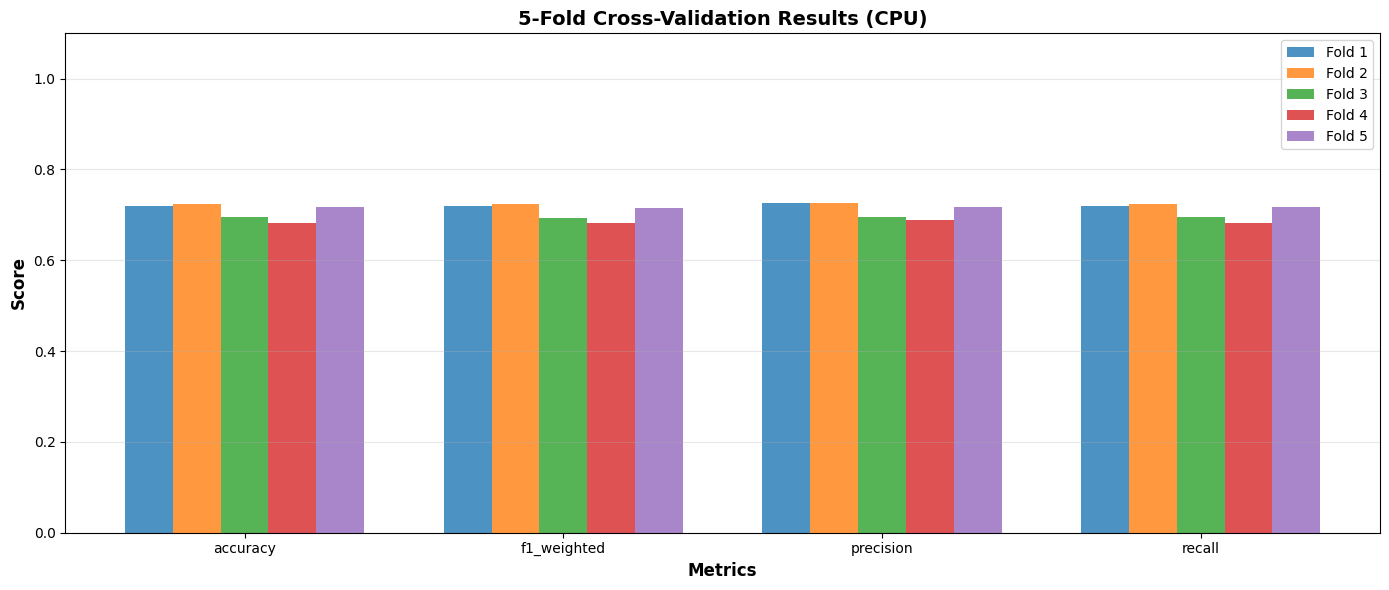

26210

In [ ]:
# SECTION 12: 5-Fold Cross-Validation (CPU) - FIXED
# Description: Robust validation using stratified 5-fold cross-validation with SMOTE in each fold
# Provides comprehensive performance assessment

print("="*70)
print("5-FOLD CROSS-VALIDATION (CPU)")
print("="*70)

# Initialize 5-fold stratified CV
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f"\n⚙️ Performing 5-fold cross-validation using {psutil.cpu_count()} CPU cores")
print("This will train 5 models and may take 10-30 minutes...\n")

cv_results = {
    'fold': [],
    'accuracy': [],
    'f1_macro': [],
    'f1_weighted': [],
    'precision': [],
    'recall': []
}

# Use original TF-IDF data for CV
X_full = X_train_tfidf
y_full = y_train

total_start = time.time()

for fold, (train_idx, val_idx) in enumerate(skf.split(X_full, y_full), 1):
    fold_start = time.time()
    print(f"Fold {fold}/5...")

    # Split fold data
    X_fold_train = X_full[train_idx]
    y_fold_train = y_full.iloc[train_idx]
    X_fold_val = X_full[val_idx]
    y_fold_val = y_full.iloc[val_idx]

    # Apply SMOTE to this fold - FIXED: removed n_jobs parameter
    smote_fold = SMOTE(random_state=42, k_neighbors=5)
    X_fold_train_balanced, y_fold_train_balanced = smote_fold.fit_resample(
        X_fold_train, y_fold_train)

    # Train model
    lr_fold = LogisticRegression(
        max_iter=1000,
        solver='lbfgs',
        multi_class='multinomial',
        random_state=42,
        n_jobs=-1,  # This is OK - LogisticRegression DOES support n_jobs
        verbose=0
    )
    lr_fold.fit(X_fold_train_balanced, y_fold_train_balanced)

    # Predict on validation
    y_fold_pred = lr_fold.predict(X_fold_val)

    # Calculate metrics
    acc = accuracy_score(y_fold_val, y_fold_pred)
    f1_m = f1_score(y_fold_val, y_fold_pred, average='macro')
    f1_w = f1_score(y_fold_val, y_fold_pred, average='weighted')
    prec = precision_score(y_fold_val, y_fold_pred, average='weighted', zero_division=0)
    rec = recall_score(y_fold_val, y_fold_pred, average='weighted', zero_division=0)

    cv_results['fold'].append(fold)
    cv_results['accuracy'].append(acc)
    cv_results['f1_macro'].append(f1_m)
    cv_results['f1_weighted'].append(f1_w)
    cv_results['precision'].append(prec)
    cv_results['recall'].append(rec)

    fold_time = time.time() - fold_start
    print(f"  Accuracy: {acc:.4f}, F1-Weighted: {f1_w:.4f}")
    print(f"  ⏱️ Fold time: {fold_time:.2f} seconds ({fold_time/60:.1f} minutes)")
    print()

total_time = time.time() - total_start

# Create DataFrame
cv_df = pd.DataFrame(cv_results)
cv_df.to_csv('cross_validation_results_tfidf_smote.csv', index=False)

print("\n" + "="*70)
print("CROSS-VALIDATION SUMMARY")
print("="*70)
print(f"\n⏱️ Total CV time: {total_time:.2f} seconds ({total_time/60:.1f} minutes)")
print("\nMean ± Std Performance Across 5 Folds:")
for metric in ['accuracy', 'f1_macro', 'f1_weighted', 'precision', 'recall']:
    mean_val = cv_df[metric].mean()
    std_val = cv_df[metric].std()
    print(f"{metric.upper():15s}: {mean_val:.4f} ± {std_val:.4f}")

print("\n✓ Cross-validation results saved to 'cross_validation_results_tfidf_smote.csv'")
print(f"💾 RAM usage: {psutil.virtual_memory().percent}%")
print("="*70 + "\n")

# Visualize CV results
plt.figure(figsize=(14, 6))
metrics_to_plot = ['accuracy', 'f1_weighted', 'precision', 'recall']
x = np.arange(len(metrics_to_plot))
width = 0.15

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for i, fold_data in cv_df.iterrows():
    values = [fold_data[m] for m in metrics_to_plot]
    plt.bar(x + i*width, values, width, label=f'Fold {int(fold_data["fold"])}',
            alpha=0.8, color=colors[i])

plt.xlabel('Metrics', fontsize=12, fontweight='bold')
plt.ylabel('Score', fontsize=12, fontweight='bold')
plt.title('5-Fold Cross-Validation Results (CPU)',
          fontsize=14, fontweight='bold')
plt.xticks(x + width*2, metrics_to_plot)
plt.legend()
plt.ylim([0, 1.1])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('cross_validation_results_tfidf_smote.png', dpi=300, bbox_inches='tight')
plt.show()

# Garbage collection
gc.collect()


#**SECTION 13: Error Analysis & Export**
Description: Analyze misclassifications and export detailed results. Identifies high-confidence errors and genre-wise error patterns.

ERROR ANALYSIS AND EXPORT
✓ Full results saved to 'full_predictions_results_tfidf_smote.csv'

ERROR ANALYSIS SUMMARY

Total test samples: 927
Correctly classified: 647 (69.80%)
Misclassified: 280 (30.20%)

High-confidence errors (>0.8): 2
Low-confidence correct predictions (<0.5): 296

✓ Misclassified samples saved to 'misclassified_samples_tfidf_smote.csv'

ERROR RATE BY GENRE (Top 20)
     Genre  Total_Samples  Errors  Error_Rate  Avg_Confidence
   romance             22      12    0.545455        0.420239
    horror            120      42    0.350000        0.462858
    travel             20       7    0.350000        0.445864
   science            129      43    0.333333        0.490291
  thriller            204      65    0.318627        0.433795
     crime            100      28    0.280000        0.499591
   fantasy            175      47    0.268571        0.511361
   history            120      29    0.241667        0.520552
    sports             17       4    0.235294       

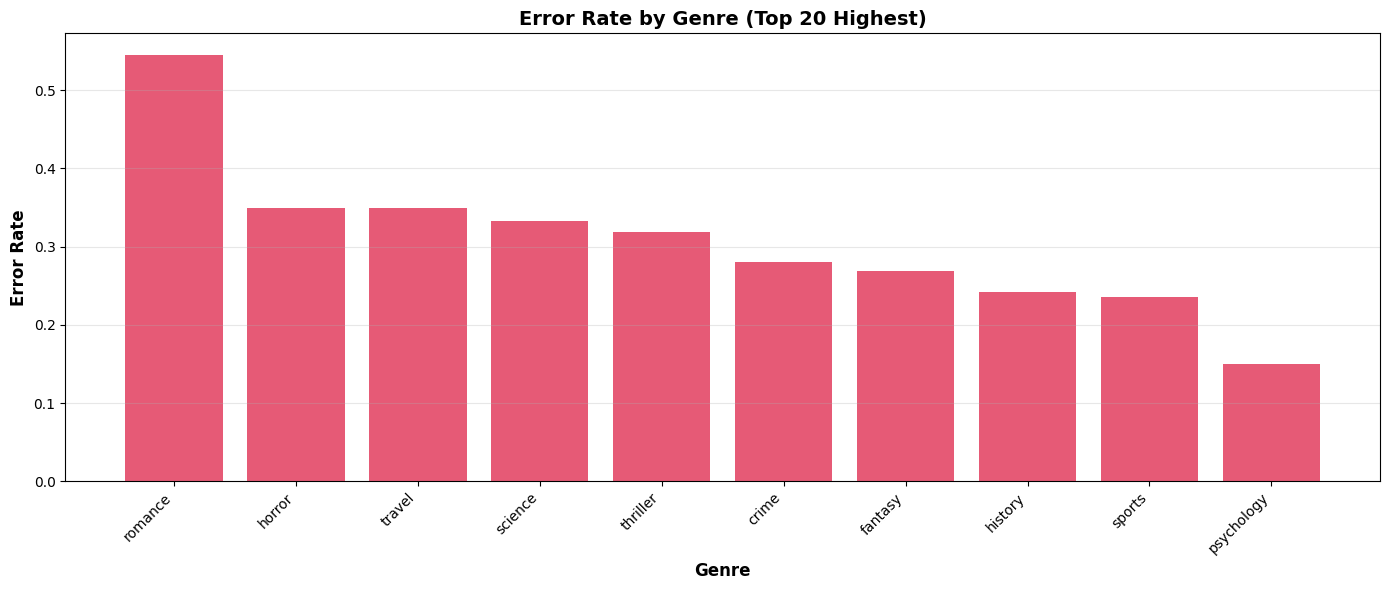


✓ Error analysis complete!


In [ ]:
# SECTION 13: Error Analysis & Export
# Description: Analyze misclassifications and export detailed results
# Identifies high-confidence errors and genre-wise error patterns

print("="*70)
print("ERROR ANALYSIS AND EXPORT")
print("="*70)

# Create results dataframe
# Use display_mapping to get the genre names based on the 0-indexed labels
results_df = pd.DataFrame({
    'text': X_test.values,
    'true_genre': [display_mapping[label][0] for label in y_test], # Use display_mapping to get genre name string
    'predicted_genre': [display_mapping[label][0] for label in y_pred], # Use display_mapping to get genre name string
    'true_label': y_test.values,
    'predicted_label': y_pred,
    'is_correct': y_test.values == y_pred
})

# Add confidence scores
max_proba = np.max(y_pred_proba, axis=1)
results_df['confidence'] = max_proba

# Top 3 predictions
top_3_predictions = []
for i in range(len(y_pred_proba)):
    top_3_idx = np.argsort(y_pred_proba[i])[-3:][::-1]
    # Use display_mapping for genre name and include classification number if desired
    top_3_str = " | ".join([f"{display_mapping[idx][0]} ({y_pred_proba[i][idx]:.3f})" # Show Genre Name
                             for idx in top_3_idx])
    top_3_predictions.append(top_3_str)
results_df['top_3_predictions'] = top_3_predictions

# Save results
results_df.to_csv('full_predictions_results_tfidf_smote.csv', index=False)
print("✓ Full results saved to 'full_predictions_results_tfidf_smote.csv'")

# Analyze misclassifications
misclassified = results_df[results_df['is_correct'] == False].copy()
misclassified = misclassified.sort_values('confidence', ascending=False)

print("\n" + "="*70)
print("ERROR ANALYSIS SUMMARY")
print("="*70)
print(f"\nTotal test samples: {len(results_df)}")
print(f"Correctly classified: {results_df['is_correct'].sum()} ({results_df['is_correct'].sum()/len(results_df)*100:.2f}%)")
print(f"Misclassified: {len(misclassified)} ({len(misclassified)/len(results_df)*100:.2f}%)")

high_conf_errors = misclassified[misclassified['confidence'] > 0.8]
print(f"\nHigh-confidence errors (>0.8): {len(high_conf_errors)}")

low_conf_correct = results_df[(results_df['is_correct'] == True) & (results_df['confidence'] < 0.5)]
print(f"Low-confidence correct predictions (<0.5): {len(low_conf_correct)}")

misclassified.to_csv('misclassified_samples_tfidf_smote.csv', index=False)
print(f"\n✓ Misclassified samples saved to 'misclassified_samples_tfidf_smote.csv'")

# Genre-wise error analysis
genre_error_analysis = []
# Iterate through unique true genres (which are now strings)
for genre in sorted(results_df['true_genre'].unique()):
    genre_samples = results_df[results_df['true_genre'] == genre]
    total = len(genre_samples)
    errors = (genre_samples['is_correct'] == False).sum()
    error_rate = errors / total if total > 0 else 0
    avg_confidence = genre_samples['confidence'].mean()

    genre_error_analysis.append({
        'Genre': genre,
        'Total_Samples': total,
        'Errors': errors,
        'Error_Rate': error_rate,
        'Avg_Confidence': avg_confidence
    })

error_analysis_df = pd.DataFrame(genre_error_analysis)
error_analysis_df = error_analysis_df.sort_values('Error_Rate', ascending=False)

print("\n" + "="*70)
print("ERROR RATE BY GENRE (Top 20)")
print("="*70)
print(error_analysis_df.head(20).to_string(index=False))

error_analysis_df.to_csv('genre_error_analysis_tfidf_smote.csv', index=False)
print("\n✓ Genre error analysis saved to 'genre_error_analysis_tfidf_smote.csv'")

# Visualize error rates (top 20 highest)
top_20_errors = error_analysis_df.head(20)
plt.figure(figsize=(14, 6))
plt.bar(top_20_errors['Genre'], top_20_errors['Error_Rate'],
        color='crimson', alpha=0.7)
plt.xlabel('Genre', fontsize=12, fontweight='bold')
plt.ylabel('Error Rate', fontsize=12, fontweight='bold')
plt.title('Error Rate by Genre (Top 20 Highest)',
          fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('error_rate_by_genre_tfidf_smote.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n" + "="*70)
print("✓ Error analysis complete!")
print("="*70)

In [ ]:
# Generate a CSV file for download containing specific test results

print("="*70)
print("GENERATING DOWNLOADABLE RESULTS FILE")
print("="*70)

# Ensure the results_df DataFrame exists and has the necessary columns
# This DataFrame is created in Section 13 (cell yPF_oKS3KtOU)
if 'results_df' in locals() and not results_df.empty:
    # Select the desired columns
    download_df = results_df[['text', 'true_genre', 'predicted_genre', 'confidence', 'top_3_predictions']].copy()

    # Add the original index as a column
    download_df['original_index'] = X_test.index

    # Reorder columns for clarity
    download_df = download_df[['original_index', 'text', 'true_genre', 'predicted_genre', 'confidence', 'top_3_predictions']]

    # Define the filename
    download_filename = 'test_predictions_for_analysis.csv'

    # Save to CSV
    download_df.to_csv(download_filename, index=False)

    print(f"✓ Results saved to '{download_filename}'. You can now download this file.")

    # Optional: Display the head of the download DataFrame to confirm
    print("\nSample of the generated download file:")
    display(download_df.head())

else:
    print("⚠️ Error: 'results_df' DataFrame not found or is empty. Please ensure Section 13 has been run successfully.")

print("\n" + "="*70)
print("✓ Download file generation complete!")
print("="*70 + "\n")

GENERATING DOWNLOADABLE RESULTS FILE
✓ Results saved to 'test_predictions_for_analysis.csv'. You can now download this file.

Sample of the generated download file:


,original_index,text,true_genre,predicted_genre,confidence,top_3_predictions
0,2131,beth successful pop music singer devout protes...,horror,crime,0.206269,crime (0.206) | thriller (0.164) | horror (0.152)
1,3211,matter goal atomic habit offer proven framewor...,psychology,psychology,0.822829,psychology (0.823) | science (0.043) | sports ...
2,3090,morning april fire alarm sound los angeles pub...,history,psychology,0.174964,psychology (0.175) | thriller (0.163) | travel...
3,3625,moment two player take court oppose side engag...,sports,sports,0.475371,sports (0.475) | psychology (0.123) | fantasy ...
4,4318,dont afraid murmur belong together abruptly ov...,fantasy,romance,0.360426,romance (0.360) | fantasy (0.205) | horror (0....



✓ Download file generation complete!



#**SECTION 14: Prediction API (Production-Ready)**
Description: Create reusable prediction function for new text inputs. Provides top-k predictions with confidence scores.

In [ ]:
# SECTION 14: Prediction API (Production-Ready)
# Description: Create reusable prediction function for new text inputs
# Provides top-k predictions with confidence scores

def predict_genre(text, tfidf_vectorizer, model, display_mapping, return_top_k=3):
    """
    Predict genre for new book synopsis (CPU-based)

    Args:
        text (str): Book synopsis
        tfidf_vectorizer: Fitted TF-IDF vectorizer
        model: Trained logistic regression model
        display_mapping (dict): 0-indexed label to (genre_name, classification_num) mapping
        return_top_k (int): Number of top predictions to return

    Returns:
        dict: Prediction results with top predictions and confidence scores
    """
    # Clean text using the same preprocessing pipeline
    cleaned_text = enhanced_clean_text(text)

    # Vectorize
    text_tfidf = tfidf_vectorizer.transform([cleaned_text])

    # Predict (on CPU)
    prediction_label = model.predict(text_tfidf)[0] # Get the 0-indexed label
    probabilities = model.predict_proba(text_tfidf)[0]

    # Get the top predicted genre name and classification number
    top_genre_name, top_classification_num = display_mapping[prediction_label]


    # Get top K predictions
    top_k_indices = np.argsort(probabilities)[-return_top_k:][::-1]

    predictions = []
    for idx in top_k_indices:
        genre_name, classification_num = display_mapping[idx]
        predictions.append({
            'label_id': idx, # Include label ID
            'genre_name': genre_name, # Include genre name
            'classification_num': classification_num, # Include classification number
            'confidence': probabilities[idx],
            'confidence_pct': f"{probabilities[idx]*100:.2f}%"
        })

    return {
        'top_prediction_label_id': prediction_label,
        'top_prediction_genre_name': top_genre_name,
        'top_prediction_classification_num': top_classification_num,
        'top_prediction_confidence': probabilities[prediction_label],
        'all_top_predictions': predictions, # Renamed for clarity
        'original_text_preview': text[:200] + "..." if len(text) > 200 else text, # Renamed
        'cleaned_text_preview': cleaned_text[:150] + "..." if len(cleaned_text) > 150 else cleaned_text # Renamed
    }

print("="*70)
print("PREDICTION API - DEMO (CPU)")
print("="*70)

# Test examples
test_synopses = [
    {
        'text': "In a distant galaxy, a young pilot discovers an ancient artifact that grants the power to control time. As evil forces close in, they must master this ability to save their home planet.",
        'expected_genre_name': "science", # Use genre name for comparison
        'expected_classification_num': 2
    },
    {
        'text': "A detective investigates mysterious murders in a small town. Each victim has a strange symbol carved into their palm. The killer may be closer than expected.",
        'expected_genre_name': "crime", # Or thriller, depending on expectation
        'expected_classification_num': 3
    },
    {
        'text': "Two childhood friends reunite after years apart. Old feelings resurface, but both are hiding secrets that could tear them apart forever.",
        'expected_genre_name': "romance",
        'expected_classification_num': 8
    }
]

# Need to reload models and vectorizer if runtime was reset
try:
    lr_model = joblib.load('logistic_regression_smote_model.pkl')
    tfidf_vectorizer = joblib.load('tfidf_vectorizer.pkl')
    # label_mapping is also loaded or recreated in Section 5, ensure display_mapping is available
    print("\n✓ Models and vectorizer loaded successfully.")
except FileNotFoundError:
    print("\n⚠️ Model files not found! Please run sections 9 and 7 first.")
    # Assuming display_mapping is available from Section 5 if notebook run sequentially

for i, example in enumerate(test_synopses, 1):
    print(f"\n{'─'*70}")
    print(f"Example {i}:")
    print(f"{'─'*70}")
    print(f"Synopsis: {example['text']}\n")

    # Pass display_mapping to the predict function
    result = predict_genre(example['text'], tfidf_vectorizer, lr_model, display_mapping)

    print(f"🎯 Top Prediction: Label {result['top_prediction_label_id']} ({result['top_prediction_genre_name']}) [Classification {result['top_prediction_classification_num']}]")
    print(f"📊 Confidence: {result['top_prediction_confidence']*100:.2f}%")
    print(f"Expected Genre: {example['expected_genre_name']} (Classification {example['expected_classification_num']})")
    print(f"\nAll Top {len(result['all_top_predictions'])} Predictions:")
    for rank, pred in enumerate(result['all_top_predictions'], 1):
        print(f"  {rank}. Label {pred['label_id']:2d} ({pred['genre_name']:<20s}) [Classification {pred['classification_num']:2d}] - {pred['confidence_pct']}")

print("\n" + "="*70)
print("✓ Prediction API ready for production use!")
print("="*70)

PREDICTION API - DEMO (CPU)

✓ Models and vectorizer loaded successfully.

──────────────────────────────────────────────────────────────────────
Example 1:
──────────────────────────────────────────────────────────────────────
Synopsis: In a distant galaxy, a young pilot discovers an ancient artifact that grants the power to control time. As evil forces close in, they must master this ability to save their home planet.

🎯 Top Prediction: Label 1 (science) [Classification 2]
📊 Confidence: 44.26%
Expected Genre: science (Classification 2)

All Top 3 Predictions:
  1. Label  1 (science             ) [Classification  2] - 44.26%
  2. Label  0 (fantasy             ) [Classification  1] - 41.46%
  3. Label  4 (horror              ) [Classification  5] - 5.33%

──────────────────────────────────────────────────────────────────────
Example 2:
──────────────────────────────────────────────────────────────────────
Synopsis: A detective investigates mysterious murders in a small town. Each victi

#**SECTION 15: Final Summary Report**
Description: Comprehensive summary of all results and deliverables. Provides complete overview of model performance and outputs.

In [ ]:
# SECTION 15: Final Summary Report
# Description: Comprehensive summary of all results and deliverables
# Provides complete overview of model performance and outputs

print("\n" + "="*70)
print(" "*10 + "FINAL SUMMARY REPORT")
print("="*70)

print("\n📊 MODEL CONFIGURATION")
print("─"*70)
print(f"Approach: TF-IDF + Logistic Regression + SMOTE (CPU-Only)")
print(f"Hardware: CPU ({psutil.cpu_count()} cores)")
print(f"Number of genres: {num_labels}")
print(f"Training samples (after SMOTE): {X_train_balanced.shape[0]:,}")
print(f"Testing samples: {len(X_test):,}")
print(f"TF-IDF features: {X_train_tfidf.shape[1]:,}")
print(f"Balancing method: SMOTE (Synthetic Minority Over-sampling)")

print("\n📈 PERFORMANCE METRICS (Test Set)")
print("─"*70)
print(f"Accuracy:            {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"F1-Score (Macro):    {f1_macro:.4f}")
print(f"F1-Score (Weighted): {f1_weighted:.4f}")
print(f"Precision:           {precision_weighted:.4f}")
print(f"Recall:              {recall_weighted:.4f}")

print("\n📈 CROSS-VALIDATION RESULTS")
print("─"*70)
for metric in ['accuracy', 'f1_weighted']:
    mean_val = cv_df[metric].mean()
    std_val = cv_df[metric].std()
    print(f"{metric.upper():20s}: {mean_val:.4f} ± {std_val:.4f}")

print("\n❌ ERROR ANALYSIS")
print("─"*70)
print(f"Total misclassifications: {len(misclassified):,}")
print(f"Error rate: {len(misclassified)/len(results_df)*100:.2f}%")
print(f"High-confidence errors: {len(high_conf_errors):,}")
if len(error_analysis_df) > 0:
    # Get genre name and classification number for most/least error-prone genres
    most_error_genre_name = error_analysis_df.iloc[0]['Genre']
    least_error_genre_name = error_analysis_df.iloc[-1]['Genre']

    # Find their label IDs using the reverse mapping (genre_name -> label_id) from display_mapping
    reverse_display_mapping = {v[0]: k for k, v in display_mapping.items()}
    most_error_label_id = reverse_display_mapping.get(most_error_genre_name, "N/A")
    least_error_label_id = reverse_display_mapping.get(least_error_genre_name, "N/A")


    print(f"Most error-prone: Label {most_error_label_id} ({most_error_genre_name}) ({error_analysis_df.iloc[0]['Error_Rate']*100:.2f}%)")
    print(f"Best performing: Label {least_error_label_id} ({least_error_genre_name}) ({error_analysis_df.iloc[-1]['Error_Rate']*100:.2f}%)")


print("\n📁 OUTPUT FILES")
print("─"*70)
print("✓ logistic_regression_smote_model.pkl")
print("✓ tfidf_vectorizer.pkl")
print("✓ label_mapping.pkl")
print("✓ full_predictions_results_tfidf_smote.csv")
print("✓ misclassified_samples_tfidf_smote.csv")
print("✓ genre_error_analysis_tfidf_smote.csv")
print("✓ cross_validation_results_tfidf_smote.csv")
print("✓ genre_distribution_before_smote.png")
print("✓ smote_comparison.png")
print("✓ confusion_matrix_tfidf_smote.png")
print("✓ per_class_performance_tfidf_smote.png")
print("✓ top_words_per_genre.png")
print("✓ cross_validation_results_tfidf_smote.png")
print("✓ error_rate_by_genre_tfidf_smote.png")

print("\n💡 KEY FEATURES")
print("─"*70)
print("✓ 100% CPU-based (no GPU required)")
print("✓ Google Colab optimized")
print("✓ Memory-efficient implementation")
print("✓ Progress tracking and timing information")
print("✓ Enhanced text cleaning with nonsensical word filtering")
print("✓ TF-IDF vectorization (5000 features, unigrams + bigrams)")
print("✓ SMOTE balancing for minority classes")
print("✓ 5-fold stratified cross-validation")
print("✓ Feature importance analysis (top words per genre)")
print("✓ Production-ready prediction API")
print("✓ Comprehensive error analysis")
print("✓ Multiple visualization outputs")

print("\n⚙️ SYSTEM RESOURCES")
print("─"*70)
print(f"CPU cores used: {psutil.cpu_count()}")
print(f"Final RAM usage: {psutil.virtual_memory().percent}%")
print(f"Available RAM: {psutil.virtual_memory().available / (1024**3):.2f} GB")

print("\n" + "="*70)
print(" "*15 + "ANALYSIS COMPLETE!")
print("="*70 + "\n")

print("🎯 This implementation is 100% CPU-compatible and optimized for Google Colab!")
print("📊 All results have been saved and are ready for analysis.")
print("🚀 Use the prediction API in Section 14 for new genre predictions.")
print("\n✅ All 15 sections completed successfully!")


          FINAL SUMMARY REPORT

📊 MODEL CONFIGURATION
──────────────────────────────────────────────────────────────────────
Approach: TF-IDF + Logistic Regression + SMOTE (CPU-Only)
Hardware: CPU (2 cores)
Number of genres: 10
Training samples (after SMOTE): 8,180
Testing samples: 927
TF-IDF features: 5,000
Balancing method: SMOTE (Synthetic Minority Over-sampling)

📈 PERFORMANCE METRICS (Test Set)
──────────────────────────────────────────────────────────────────────
Accuracy:            0.6980 (69.80%)
F1-Score (Macro):    0.6921
F1-Score (Weighted): 0.6990
Precision:           0.7032
Recall:              0.6980

📈 CROSS-VALIDATION RESULTS
──────────────────────────────────────────────────────────────────────
ACCURACY            : 0.7074 ± 0.0183
F1_WEIGHTED         : 0.7071 ± 0.0178

❌ ERROR ANALYSIS
──────────────────────────────────────────────────────────────────────
Total misclassifications: 280
Error rate: 30.20%
High-confidence errors: 2
Most error-prone: Label 7 (romance) (